# Chapter 7. Overfitting and Regularization
## Rahul Bhadani

# 1. L2 Surface

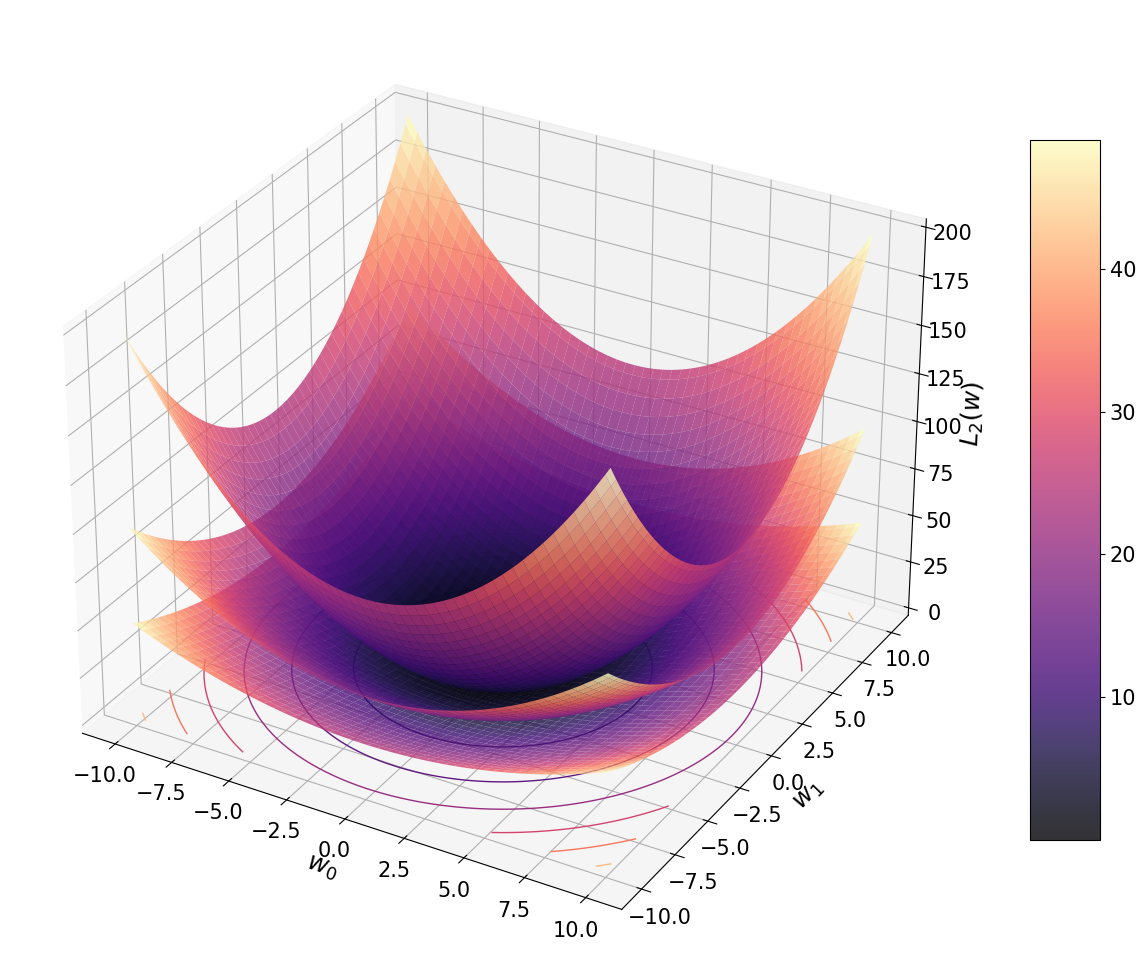

In [2]:
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams['font.size'] = 15
w0 = np.linspace(-10, 10, 100)
w1 = np.linspace(-10, 10, 100)
W0, W1 = np.meshgrid(w0, w1)

# Define the Gaussian function for a single peak
Lambda = 0.25
Z = Lambda*(W0**2 + W1**2)

# Create the 3D plot
fig = plt.figure(figsize=(12, 14))
ax = fig.add_subplot(111, projection='3d')
surf = ax.plot_surface(W0, W1, Z, cmap='magma', edgecolor='none', alpha = 0.8)
cset_xy = ax.contour(W0, W1, Z, zdir='z', offset=np.min(Z), cmap='magma', linewidths=1)

Lambda = 0.50
Z = Lambda*(W0**2 + W1**2)
ax.plot_surface(W0, W1, Z, cmap='magma', edgecolor='none', alpha = 0.8)

Lambda = 1.0
Z = Lambda*(W0**2 + W1**2)
ax.plot_surface(W0, W1, Z, cmap='magma', edgecolor='none', alpha = 0.8)


# Add labels and title
ax.set_xlabel('$w_0$', fontsize=18)
ax.set_ylabel('$w_1$', fontsize=18)
ax.set_zlabel('$L_2(w)$', fontsize=18)
plt.tight_layout(pad=0.0)
ax.xaxis.set_visible(False)
ax.yaxis.set_visible(False)
fig.patch.set_alpha(0.8)
fig.colorbar(surf, ax=ax, shrink=0.5, aspect=10)
plt.savefig('figures/L2_Penalty.pdf', transparent=True)
# Show the plot
plt.show()

# 2. L1 Surface

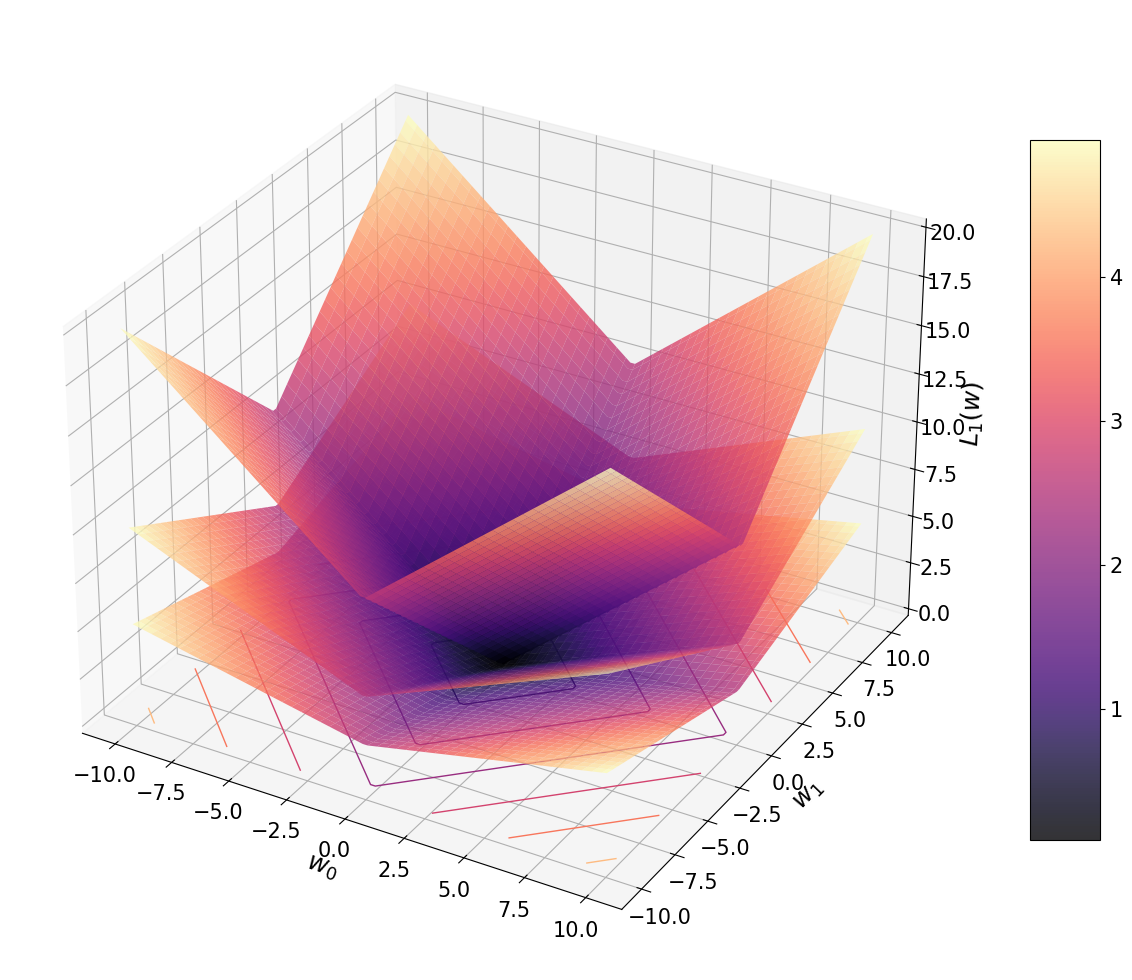

In [3]:
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams['font.size'] = 15
w0 = np.linspace(-10, 10, 100)
w1 = np.linspace(-10, 10, 100)
W0, W1 = np.meshgrid(w0, w1)

# Define the Gaussian function for a single peak
Lambda = 0.25
Z = Lambda*(np.abs(W0) + np.abs(W1))

# Create the 3D plot
fig = plt.figure(figsize=(12, 14))
ax = fig.add_subplot(111, projection='3d')
surf = ax.plot_surface(W0, W1, Z, cmap='magma', edgecolor='none', alpha = 0.8)
cset_xy = ax.contour(W0, W1, Z, zdir='z', offset=np.min(Z), cmap='magma', linewidths=1)

Lambda = 0.50
Z = Lambda*(np.abs(W0) + np.abs(W1))
ax.plot_surface(W0, W1, Z, cmap='magma', edgecolor='none', alpha = 0.8)

Lambda = 1.0
Z = Lambda*(np.abs(W0) + np.abs(W1))
ax.plot_surface(W0, W1, Z, cmap='magma', edgecolor='none', alpha = 0.8)


# Add labels and title
ax.set_xlabel('$w_0$', fontsize=18)
ax.set_ylabel('$w_1$', fontsize=18)
ax.set_zlabel('$L_1(w)$', fontsize=18)
plt.tight_layout(pad=0.0)
ax.xaxis.set_visible(False)
ax.yaxis.set_visible(False)
fig.patch.set_alpha(0.8)
fig.colorbar(surf, ax=ax, shrink=0.5, aspect=10)
plt.savefig('figures/L1_Penalty.pdf', transparent=True)
# Show the plot
plt.show()

# 3. Overfitting Demo

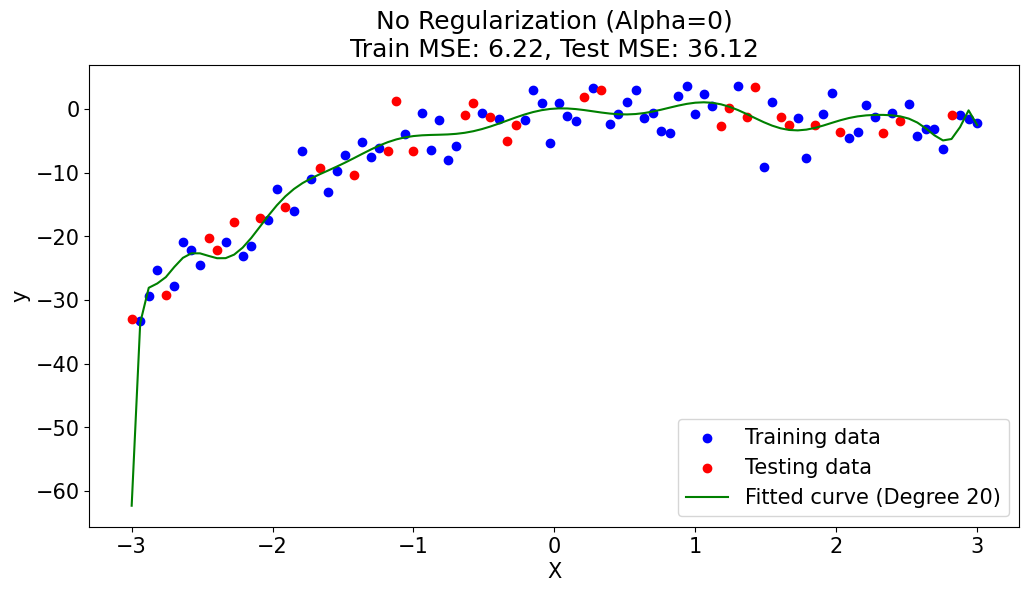

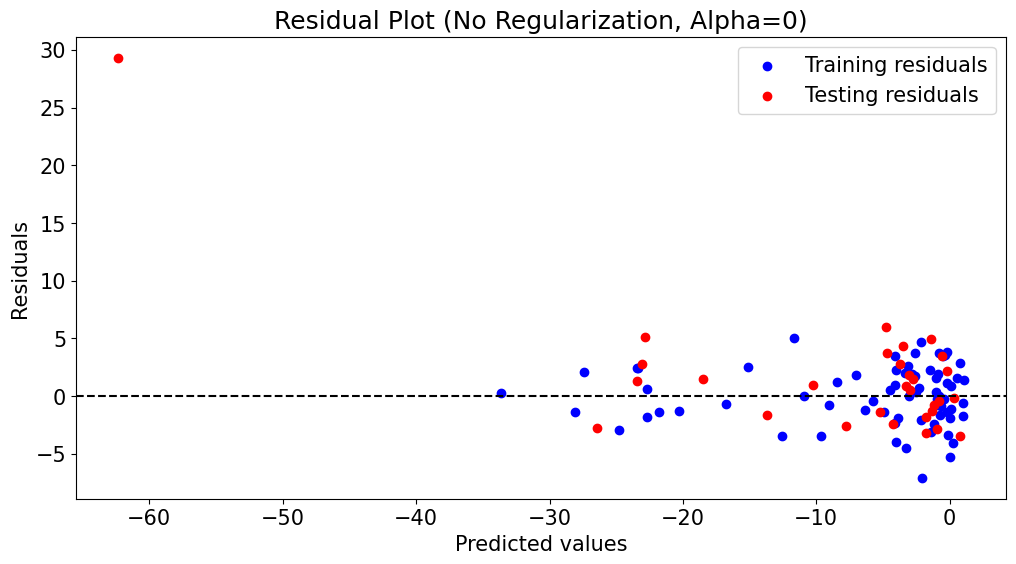

/home/refulgent/VersionControl/CPE486586_FA25/Code/.venv/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 3.248e+02, tolerance: 5.552e-01
  model = cd_fast.enet_coordinate_descent(


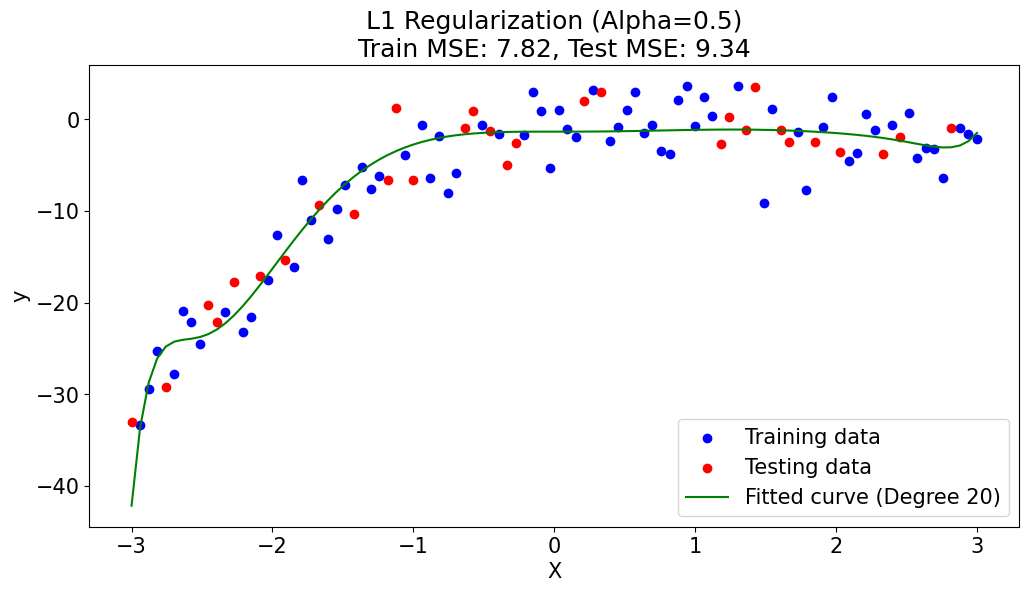

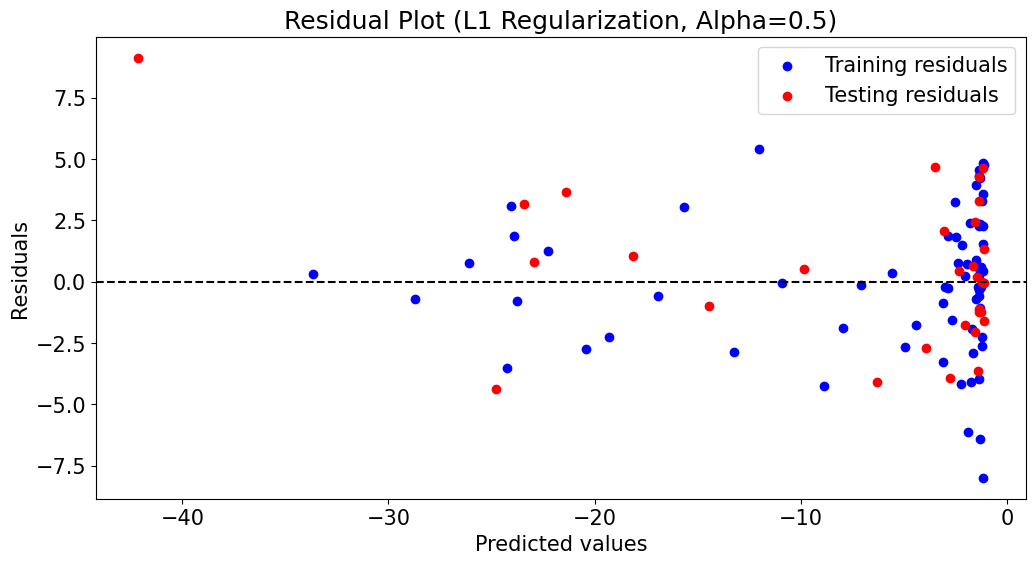

/home/refulgent/VersionControl/CPE486586_FA25/Code/.venv/lib/python3.12/site-packages/scipy/_lib/_util.py:1233: LinAlgWarning: Ill-conditioned matrix (rcond=1.47383e-20): result may not be accurate.
  return f(*arrays, *other_args, **kwargs)


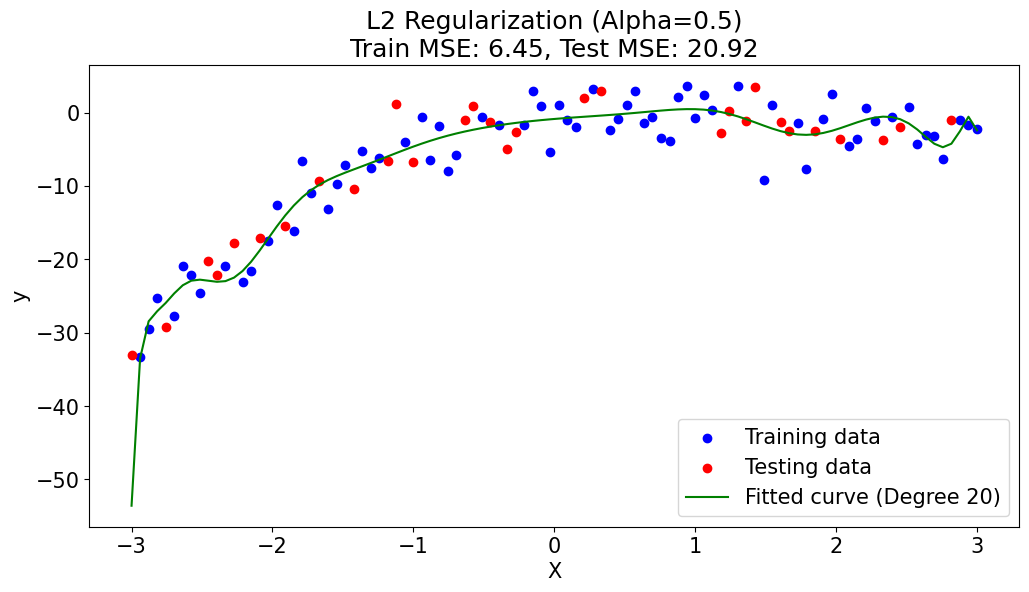

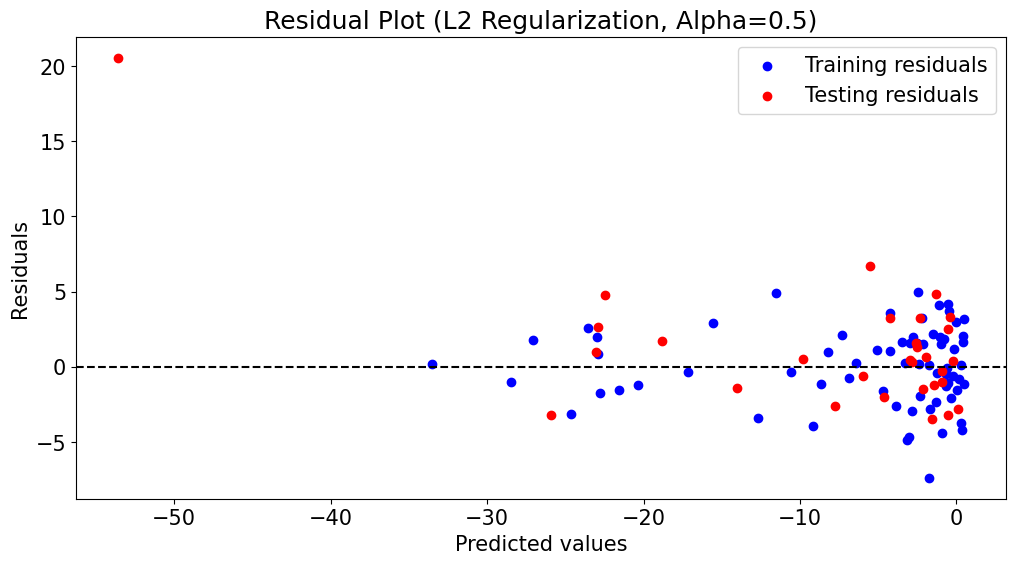

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.metrics import mean_squared_error
from sklearn.pipeline import make_pipeline

# Generate synthetic dataset
np.random.seed(42)
X = np.linspace(-3, 3, 100)
y = 0.5 * X**3 - 2 * X**2 + X + np.random.normal(0, 3, 100)

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Reshape X for sklearn
X_train = X_train.reshape(-1, 1)
X_test = X_test.reshape(-1, 1)

# Function to fit polynomial regression and plot results
def fit_and_plot(X_train, y_train, X_test, y_test, degree, alpha=0, regularization=None):
    if regularization == 'l1':
        model = make_pipeline(PolynomialFeatures(degree), Lasso(alpha=alpha))
    elif regularization == 'l2':
        model = make_pipeline(PolynomialFeatures(degree), Ridge(alpha=alpha))
    else:
        model = make_pipeline(PolynomialFeatures(degree), LinearRegression())
    
    model.fit(X_train, y_train)
    y_train_pred = model.predict(X_train)
    y_test_pred = model.predict(X_test)
    
    # Calculate MSE
    train_mse = mean_squared_error(y_train, y_train_pred)
    test_mse = mean_squared_error(y_test, y_test_pred)
    
    # Plot the results
    plt.figure(figsize=(12, 6))
    
    # Plot the data points
    plt.scatter(X_train, y_train, color='blue', label='Training data')
    plt.scatter(X_test, y_test, color='red', label='Testing data')
    
    # Plot the fitted curve
    X_plot = np.linspace(-3, 3, 100).reshape(-1, 1)
    y_plot = model.predict(X_plot)
    plt.plot(X_plot, y_plot, color='green', label=f'Fitted curve (Degree {degree})')
    
    # Handle the case where regularization is None
    regularization_title = 'No Regularization' if regularization is None else f'{regularization.upper()} Regularization'
    plt.title(f'{regularization_title} (Alpha={alpha})\nTrain MSE: {train_mse:.2f}, Test MSE: {test_mse:.2f}')
    plt.xlabel('X')
    plt.ylabel('y')
    plt.legend()
    plt.show()
    
    # Residual plot
    residuals_train = y_train - y_train_pred
    residuals_test = y_test - y_test_pred
    
    plt.figure(figsize=(12, 6))
    plt.scatter(y_train_pred, residuals_train, color='blue', label='Training residuals')
    plt.scatter(y_test_pred, residuals_test, color='red', label='Testing residuals')
    plt.axhline(0, color='black', linestyle='--')
    plt.title(f'Residual Plot ({regularization_title}, Alpha={alpha})')
    plt.xlabel('Predicted values')
    plt.ylabel('Residuals')
    plt.legend()
    plt.show()

# Fit polynomial regression without regularization (overfitting)
fit_and_plot(X_train, y_train, X_test, y_test, degree=20, regularization=None)

# Fit polynomial regression with L1 regularization (Lasso)
fit_and_plot(X_train, y_train, X_test, y_test, degree=20, alpha=0.5, regularization='l1')

# Fit polynomial regression with L2 regularization (Ridge)
fit_and_plot(X_train, y_train, X_test, y_test, degree=20, alpha=0.5, regularization='l2')

- Without regularization, the model overfits the training data, resulting in a low training MSE but a high testing MSE.
- With L1 or L2 regularization, the model generalizes well, reducing overfitting and improving the testing MSE.
- Residual plots help identify patterns in errors, which can indicate overfitting or underfitting.

# 4. Overfitting with Outliers (When Regularization Doesn't Help)

### Regularization may not help when my model is simple, i.e. when their is model bias. The following example shows it.

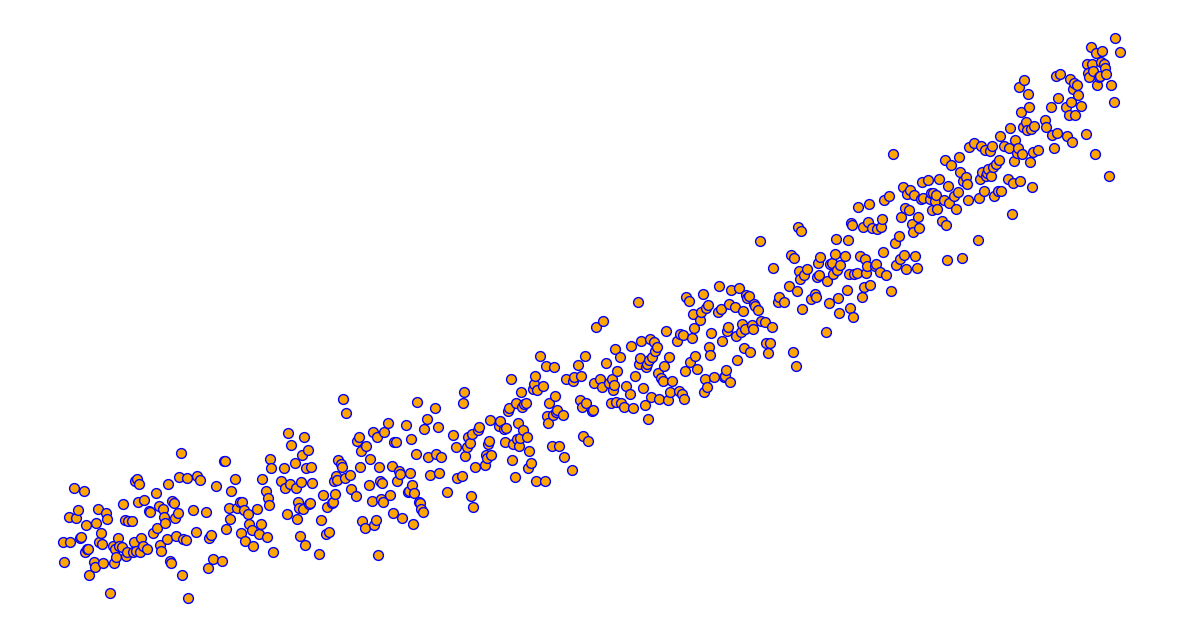

In [5]:
import numpy as np
import matplotlib.pyplot as plt

# Generate x values
x_uniform = np.linspace(0, 25, 1000)
# Randomly remove some points to create sparse regions
keep_indices = np.random.rand(1000) > 0.4  # Keep 70% of points
x = x_uniform[keep_indices]

# Create a line equation with some quadratic
y = 3.0*x + 77.0 + 0.4*x*x

# Add Gaussian noise
mu = 0.5  # Mean of the Gaussian noise
sigma = 20  # Standard deviation of the Gaussian noise
noise = np.random.normal(mu, sigma, y.shape)
y_noisy = y + noise

## Make a plot
# Plot the results
fig, ax = plt.subplots(figsize=(15, 8))
plt.scatter(x, y_noisy, c='orange', edgecolors='blue', s=50)

plt.axis('off')
ax.xaxis.set_visible(False)
ax.yaxis.set_visible(False)
ax.set_frame_on(False)
fig.patch.set_alpha(0.0)
plt.savefig('figures/scatterplot.png', transparent=True)
plt.show()

[12.9149618]
39.75419692588156
R^2 (Coefficient of Determination): 0.9609611432418586
MSE On Training Data= 766.2708726024965
MSE On Testing Data= 825.9063309653609


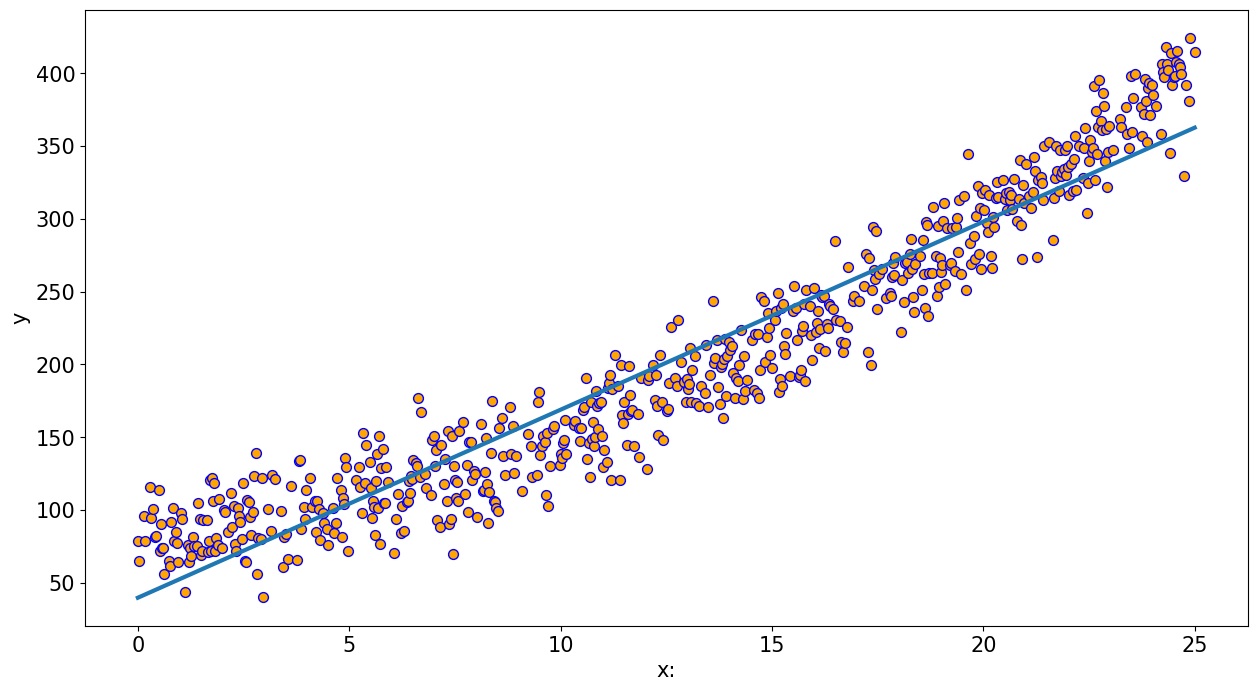

In [6]:
from sklearn.linear_model import LinearRegression
import sklearn.metrics as sm

X_train, X_test, y_train, y_test = train_test_split(x, y_noisy, test_size=1/3, random_state=0)

L = LinearRegression()
reg= L.fit(X_train.reshape((-1, 1)), y_train)
print(reg.coef_) # w_1
print(reg.intercept_) #w_0
fig, ax = plt.subplots(figsize=(15, 8))
plt.scatter(x, y_noisy, c='orange', edgecolors='blue', s=50)
fig.patch.set_alpha(0.0)
plt.xlabel('x:')
plt.ylabel('y')
yhat = reg.coef_*x + reg.intercept_
plt.plot(x, yhat, linewidth=3)

r_squared = reg.score(x.reshape((-1, 1)), y)
print("R^2 (Coefficient of Determination):", r_squared)

Y_Pred = L.predict(X_train.reshape((-1, 1)))

e= sm.mean_squared_error(y_train, Y_Pred)
print("MSE On Training Data= {}".format(e))

Y_Pred = L.predict(X_test.reshape((-1, 1)))

e= sm.mean_squared_error(y_test, Y_Pred)
print("MSE On Testing Data= {}".format(e))


## Now add a few outliers

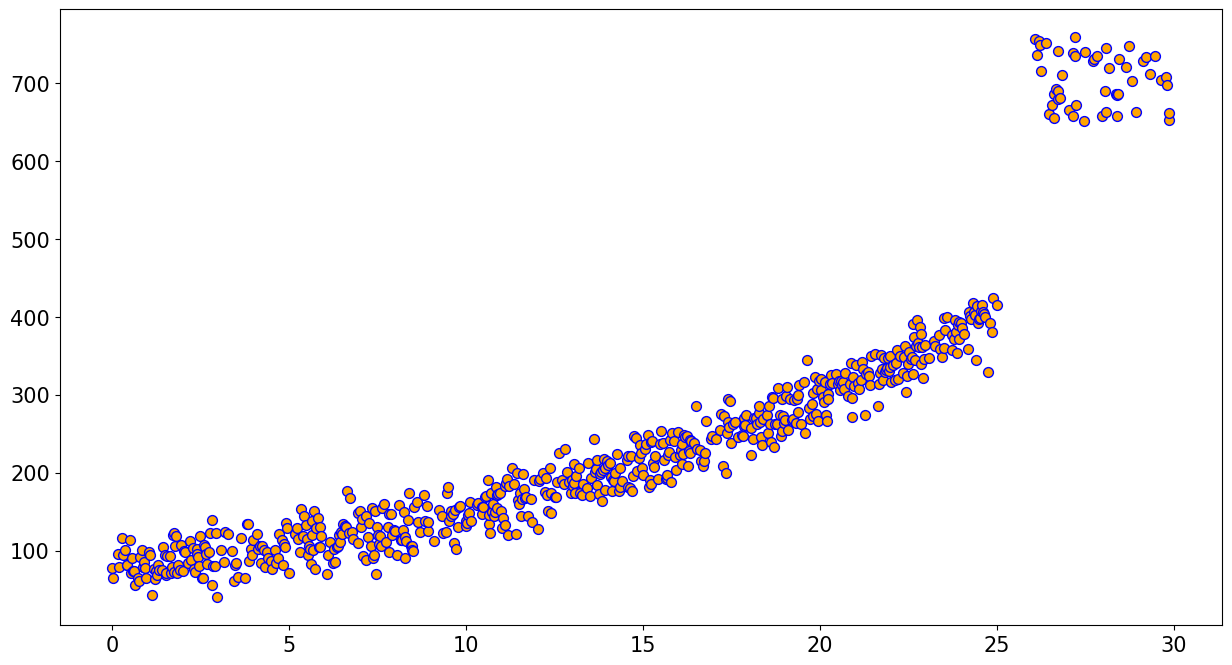

In [7]:
# Add a few outliers
# Add outliers
np.random.seed(42)  # For reproducibility
num_outliers = 3  # Number of outliers to add

x_outliers = np.sort(np.random.uniform(26, 30, 50))
# Generate extreme y values (far above the trend)
y_outliers = np.random.uniform(650, 760, 50)  # Asymmetric - only high values


# Append outliers to the original data
x_with_outliers = np.concatenate([x, x_outliers])
y_noisy_with_outliers = np.concatenate([y_noisy, y_outliers])


## Make a plot
# Plot the results
fig, ax = plt.subplots(figsize=(15, 8))
plt.scatter(x_with_outliers, y_noisy_with_outliers, c='orange', edgecolors='blue', s=50)
#plt.axis('off')
# ax.xaxis.set_visible(False)
# ax.yaxis.set_visible(False)
# ax.set_frame_on(False)
# fig.patch.set_alpha(0.0)
plt.show()


## Now, we fit a linear model to it without regularization

[17.66535534]
-4.526977266500239
R^2 (Coefficient of Determination): 0.797086764175788
MSE On Training Data= 5725.590478343219
MSE On Testing Data= 5889.561247776664


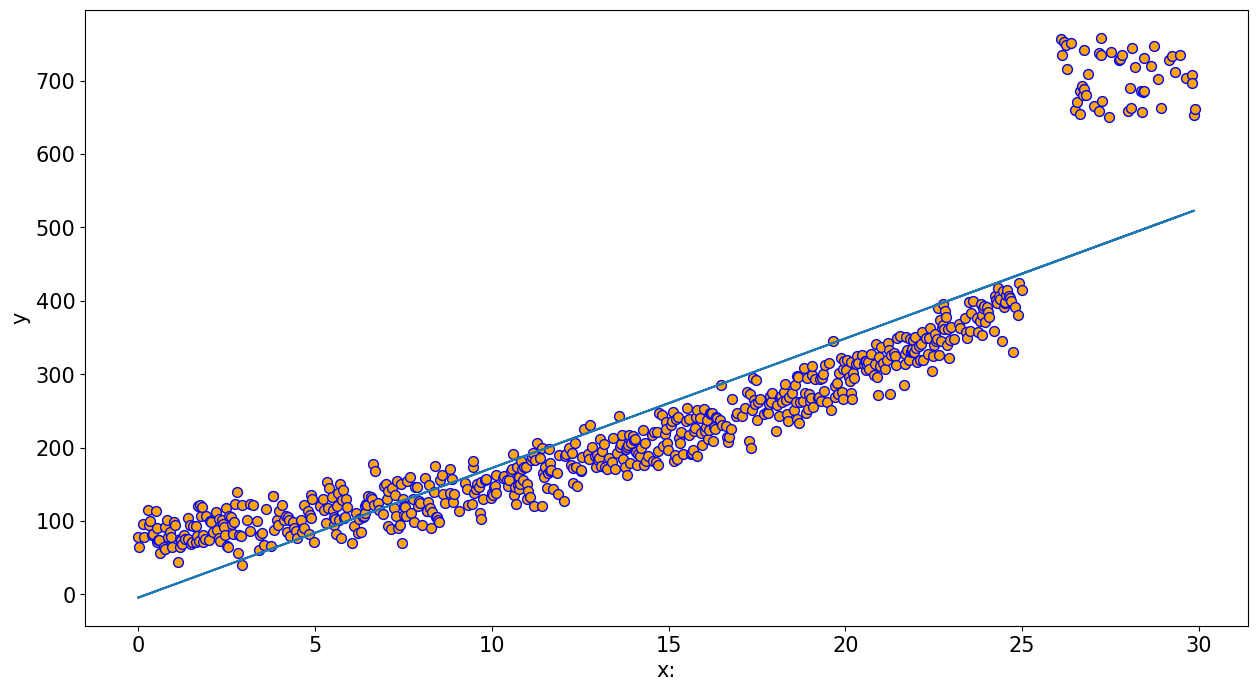

In [8]:
from sklearn.linear_model import LinearRegression

X_train, X_test, y_train, y_test = train_test_split(x_with_outliers, y_noisy_with_outliers, test_size=1/3, random_state=0)

L = LinearRegression()
reg= L.fit(X_train.reshape((-1, 1)), y_train)

print(reg.coef_) # w_1
print(reg.intercept_) #w_0
fig, ax = plt.subplots(figsize=(15, 8))
plt.scatter(x_with_outliers, y_noisy_with_outliers, c='orange', edgecolors='blue', s=50)
fig.patch.set_alpha(0.0)
plt.xlabel('x:')
plt.ylabel('y')
yhat = reg.coef_*X_train + reg.intercept_
plt.plot(X_train, yhat)

r_squared = reg.score(x.reshape((-1, 1)), y)
print("R^2 (Coefficient of Determination):", r_squared)

Y_Pred = L.predict(X_train.reshape((-1, 1)))

e= sm.mean_squared_error(y_train, Y_Pred)
print("MSE On Training Data= {}".format(e))

Y_Pred = L.predict(X_test.reshape((-1, 1)))

e= sm.mean_squared_error(y_test, Y_Pred)
print("MSE On Testing Data= {}".format(e))

## Now use L2 regularization

Coefficient (w_1): [17.66287535]
Intercept (w_0): -4.492617319831396
R^2 (Coefficient of Determination): 0.7780705253501666
MSE On Training Data= 5725.590869448165
MSE On Testing Data= 5889.745283031308


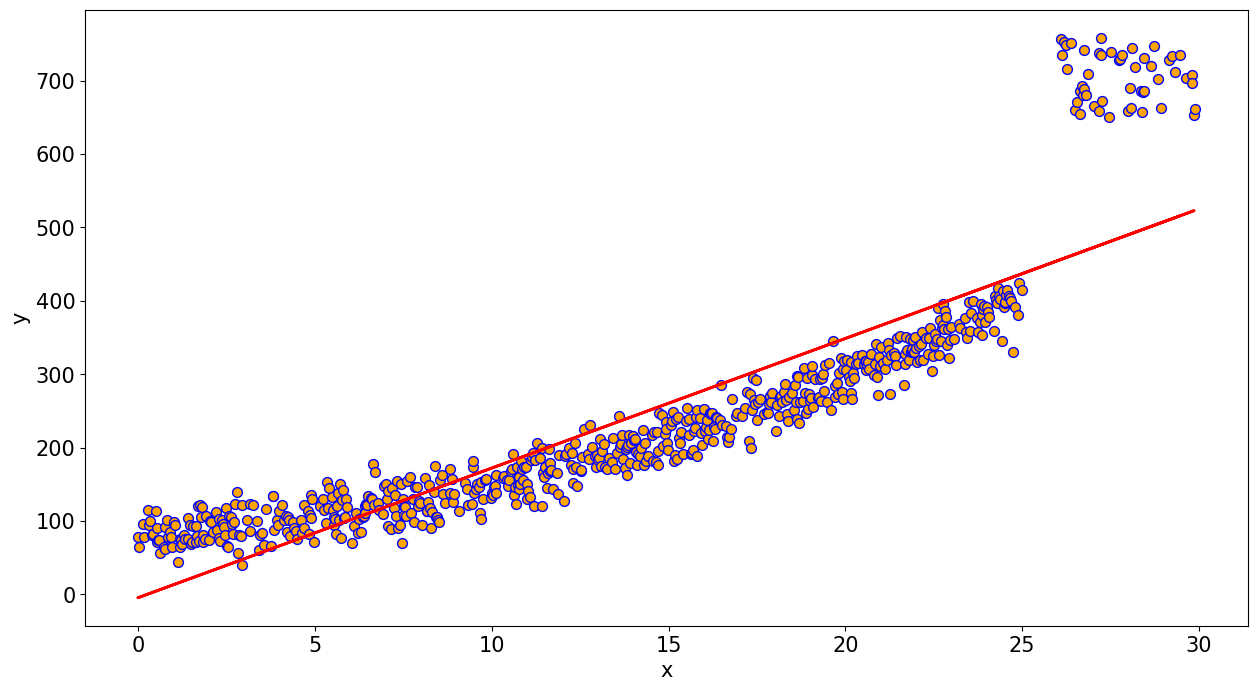

In [9]:
from sklearn.linear_model import Ridge



# Apply Ridge Regression (L2 regularization)
alpha = 4.0  # Regularization strength (you can tune this)
R = Ridge(alpha=alpha).fit(x_with_outliers.reshape((-1, 1)), y_noisy_with_outliers)

reg = R.fit(X_train.reshape((-1, 1)), y_train)

# Print coefficients
print("Coefficient (w_1):", reg.coef_)
print("Intercept (w_0):", reg.intercept_)

# Plot the data
fig, ax = plt.subplots(figsize=(15, 8))
plt.scatter(x_with_outliers, y_noisy_with_outliers, c='orange', edgecolors='blue', s=50)
fig.patch.set_alpha(0.0)
plt.xlabel('x')
plt.ylabel('y')

# Plot the fitted line
yhat = reg.coef_ * X_train + reg.intercept_
plt.plot(X_train, yhat, label='Ridge Regression Fit', color='red', linewidth=2)

# Calculate R^2 (Coefficient of Determination)
r_squared = reg.score(x_with_outliers.reshape((-1, 1)), y_noisy_with_outliers)
print("R^2 (Coefficient of Determination):", r_squared)

Y_Pred = R.predict(X_train.reshape((-1, 1)))

e= sm.mean_squared_error(y_train, Y_Pred)
print("MSE On Training Data= {}".format(e))

Y_Pred = R.predict(X_test.reshape((-1, 1)))

e= sm.mean_squared_error(y_test, Y_Pred)
print("MSE On Testing Data= {}".format(e))

## L1 Regularization

Coefficient (w_1): [17.60245304]
Intercept (w_0): -3.655473856048701
R^2 (Coefficient of Determination): 0.7780036249173606
MSE On Training Data= 5725.842087550244
MSE On Testing Data= 5894.470253077961


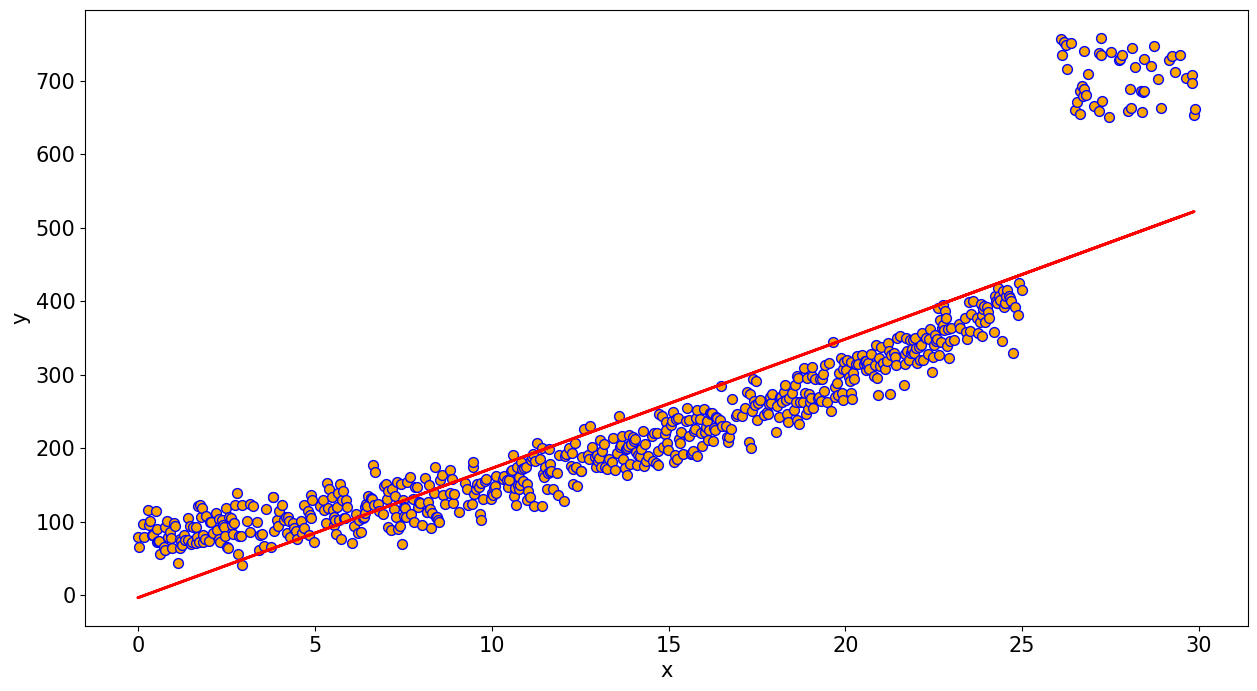

In [10]:
from sklearn.linear_model import Lasso



# Apply Lasso Regression (L2 regularization)
alpha = 4.0  # Regularization strength (you can tune this)
R = Lasso(alpha=alpha).fit(x_with_outliers.reshape((-1, 1)), y_noisy_with_outliers)

reg = R.fit(X_train.reshape((-1, 1)), y_train)

# Print coefficients
print("Coefficient (w_1):", reg.coef_)
print("Intercept (w_0):", reg.intercept_)

# Plot the data
fig, ax = plt.subplots(figsize=(15, 8))
plt.scatter(x_with_outliers, y_noisy_with_outliers, c='orange', edgecolors='blue', s=50)
fig.patch.set_alpha(0.0)
plt.xlabel('x')
plt.ylabel('y')

# Plot the fitted line
yhat = reg.coef_ * X_train + reg.intercept_
plt.plot(X_train, yhat, label='Ridge Regression Fit', color='red', linewidth=2)

# Calculate R^2 (Coefficient of Determination)
r_squared = reg.score(x_with_outliers.reshape((-1, 1)), y_noisy_with_outliers)
print("R^2 (Coefficient of Determination):", r_squared)

Y_Pred = R.predict(X_train.reshape((-1, 1)))

e= sm.mean_squared_error(y_train, Y_Pred)
print("MSE On Training Data= {}".format(e))

Y_Pred = R.predict(X_test.reshape((-1, 1)))

e= sm.mean_squared_error(y_test, Y_Pred)
print("MSE On Testing Data= {}".format(e))

## Linear Regression without Regularization with PyTorch

Epoch [1000/20000], Loss: 5727.9634
Epoch [2000/20000], Loss: 5726.4702
Epoch [3000/20000], Loss: 5725.9165
Epoch [4000/20000], Loss: 5725.7114
Epoch [5000/20000], Loss: 5725.6353
Epoch [6000/20000], Loss: 5725.6069
Epoch [7000/20000], Loss: 5725.5962
Epoch [8000/20000], Loss: 5725.5913
Epoch [9000/20000], Loss: 5725.5908
Epoch [10000/20000], Loss: 5725.5903
Epoch [11000/20000], Loss: 5725.5898
Epoch [12000/20000], Loss: 5725.5908
Epoch [13000/20000], Loss: 5725.5903
Epoch [14000/20000], Loss: 5725.5903
Epoch [15000/20000], Loss: 5725.5903
Epoch [16000/20000], Loss: 5725.5903
Epoch [17000/20000], Loss: 5725.5898
Epoch [18000/20000], Loss: 5725.5903
Epoch [19000/20000], Loss: 5725.5898
Epoch [20000/20000], Loss: 5725.5898
Learned weight w1: 17.6653
Learned weight w0: -4.5264


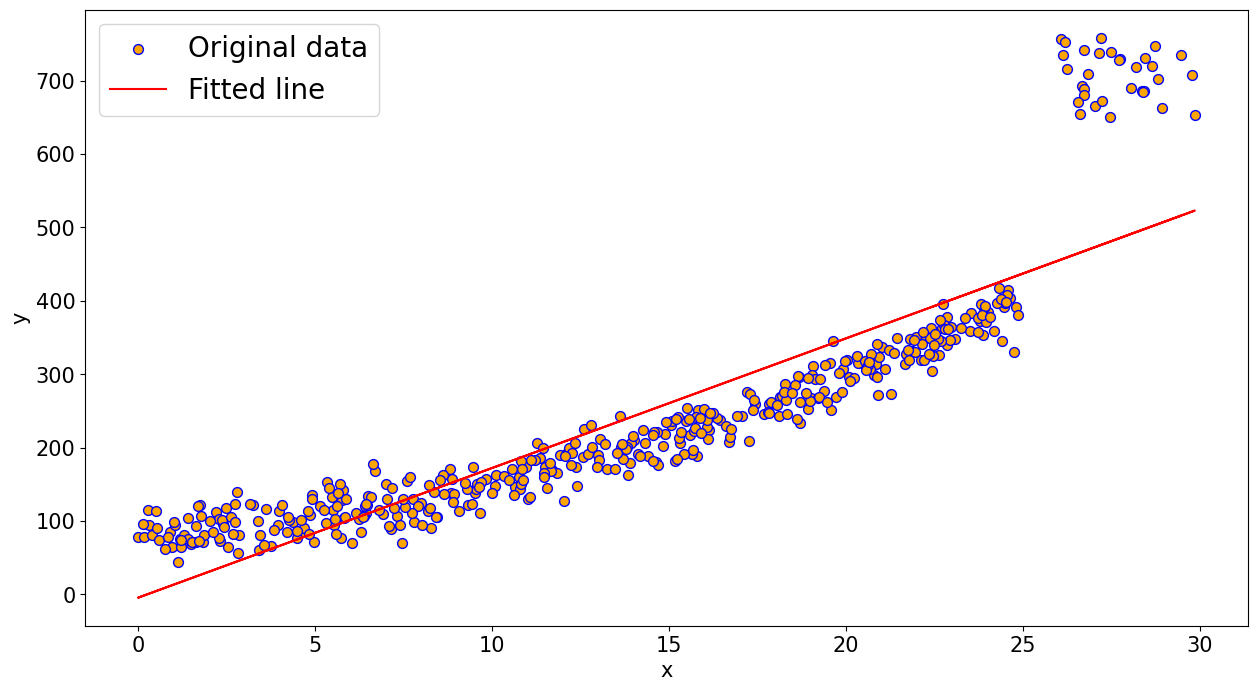

In [11]:
import torch
import numpy as np
import matplotlib.pyplot as plt


# Convert scaled data to PyTorch tensors
X = torch.tensor(X_train, dtype=torch.float32)
Y = torch.tensor(y_train, dtype=torch.float32)

# Initialize parameters (weights)
w_1 = torch.randn(1, requires_grad=True, dtype=torch.float32)  # Weight for X
w_0 = torch.randn(1, requires_grad=True, dtype=torch.float32)  # Bias term

# Lists to store w_1, w_0 values over epochs
w_1_vals = []
w_0_vals = []

# Define the Linear Regression model manually
def model(X):
    return w_1 * X + w_0

# Loss function: Mean Squared Error
def mse_loss(Y_pred, Y_true):
    return torch.mean((Y_pred - Y_true)**2)

# Optimizer: Using SGD (Stochastic Gradient Descent)
learning_rate = 0.001  # Adjusted learning rate
epochs = 20000
for epoch in range(epochs):
    # Forward pass: Compute predicted y
    Y_pred = model(X)
    
    # Compute loss
    loss = mse_loss(Y_pred, Y)
    
    # Backward pass: Compute gradients
    loss.backward()
    
    # Update parameters manually
    with torch.no_grad():
        w_1 -= learning_rate * w_1.grad
        w_0 -= learning_rate * w_0.grad
        
        # Zero the gradients after updating
        w_1.grad.zero_()
        w_0.grad.zero_()
        
    # Store the values of w_1 and w_0 at each epoch
    w_1_vals.append(w_1.item())
    w_0_vals.append(w_0.item())
    
    # Print the loss every 10 epochs
    if (epoch+1) % 1000 == 0:
        print(f'Epoch [{epoch+1}/{epochs}], Loss: {loss.item():.4f}')

# Print the learned parameters
print(f'Learned weight w1: {w_1.item():.4f}')
print(f'Learned weight w0: {w_0.item():.4f}')

# Predict on scaled X
y_pred = model(X).detach().numpy()


# Plot the results
fig, ax = plt.subplots(figsize=(15, 8))
plt.rcParams['font.size'] = 20
plt.scatter(X_train, y_train, label='Original data',  c='orange', edgecolors='blue', s=50)
plt.plot(X_train, y_pred, label='Fitted line', color='red')
plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.show()

In [12]:
# Predictions

# MSE (Mean Squared Error)
MSE = np.mean((y_train - y_pred) ** 2)

print(f'MSE: {MSE}')
# SSE (Sum of Squared Errors)
SSE = np.sum((y_train - y_pred) ** 2)

# SSTO (Total Sum of Squares)
SSTO = np.sum((y_train - np.mean(y_noisy_with_outliers)) ** 2)

# R-squared
R_squared = 1 - (SSE / SSTO)

# Print the R-squared value
print(f'R-squared: {R_squared.item():.4f}')

MSE: 5725.590258881015
R-squared: 0.7761


## Linear Regression with Regularization with PyTorch

Epoch [1000/20000], Loss: 5758.5239
Epoch [2000/20000], Loss: 5758.1099
Epoch [3000/20000], Loss: 5758.0059
Epoch [4000/20000], Loss: 5757.9810
Epoch [5000/20000], Loss: 5757.9741
Epoch [6000/20000], Loss: 5757.9727
Epoch [7000/20000], Loss: 5757.9727
Epoch [8000/20000], Loss: 5757.9727
Epoch [9000/20000], Loss: 5757.9727
Epoch [10000/20000], Loss: 5757.9727
Epoch [11000/20000], Loss: 5757.9722
Epoch [12000/20000], Loss: 5757.9727
Epoch [13000/20000], Loss: 5757.9722
Epoch [14000/20000], Loss: 5757.9722
Epoch [15000/20000], Loss: 5757.9722
Epoch [16000/20000], Loss: 5757.9722
Epoch [17000/20000], Loss: 5757.9722
Epoch [18000/20000], Loss: 5757.9722
Epoch [19000/20000], Loss: 5757.9722
Epoch [20000/20000], Loss: 5757.9722
Learned weight w1: 17.5733
Learned weight w0: -2.9559


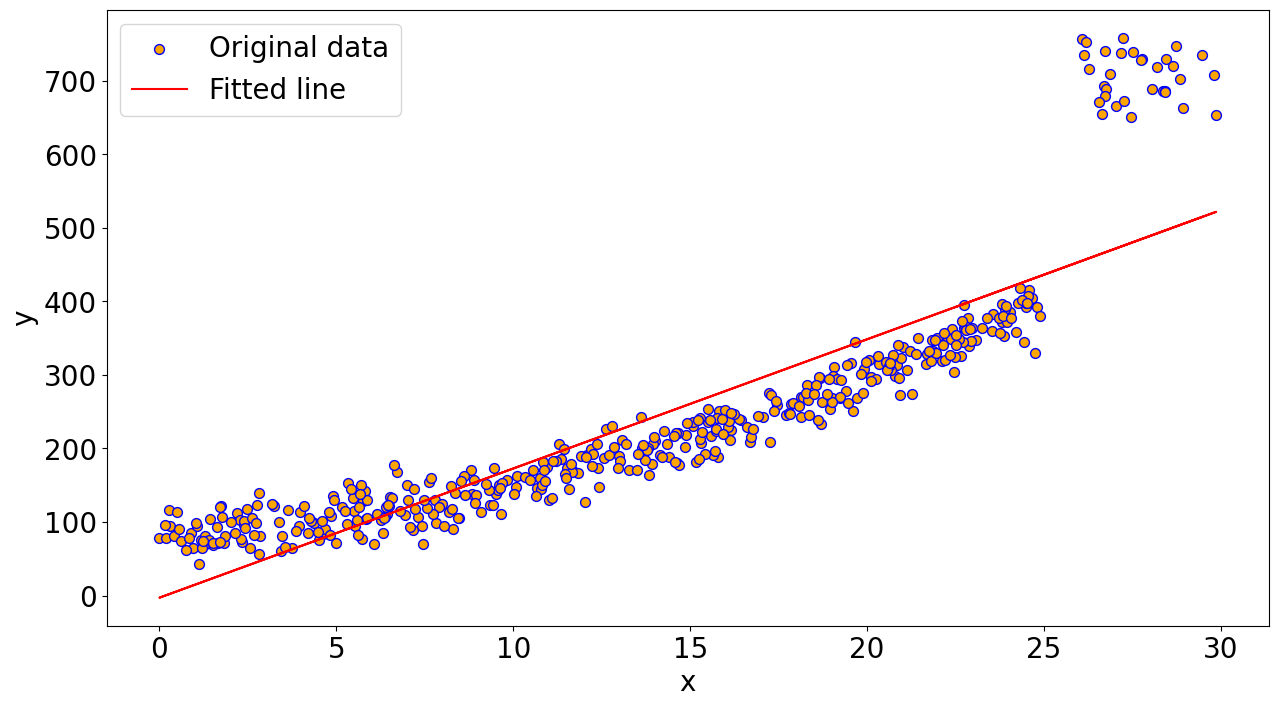

In [13]:
import torch
import numpy as np
import matplotlib.pyplot as plt


# Convert scaled data to PyTorch tensors
X = torch.tensor(X_train, dtype=torch.float32)
Y = torch.tensor(y_train, dtype=torch.float32)

# Initialize parameters (weights)
w_1 = torch.randn(1, requires_grad=True, dtype=torch.float32)  # Weight for X
w_0 = torch.randn(1, requires_grad=True, dtype=torch.float32)  # Bias term

# Lists to store w_1, w_0 values over epochs
w_1_vals = []
w_0_vals = []

# Define the Linear Regression model manually
def model(X):
    return w_1 * X + w_0

# Loss function: Mean Squared Error
def mse_loss_with_l2(Y_pred, Y_true, w_1, w_0, l2_lambda):
    # Mean Squared Error
    mse = torch.mean((Y_pred - Y_true)**2)
    # L2 Regularization term
    l2_penalty = l2_lambda * (w_1**2 + w_0**2)
    # Total loss
    return mse + l2_penalty

# Optimizer: Using SGD (Stochastic Gradient Descent)
learning_rate = 0.001  # Adjusted learning rate
epochs = 20000
l2_lambda = 0.1  # Regularization strength (you can tune this)

for epoch in range(epochs):
    # Forward pass: Compute predicted y
    Y_pred = model(X)
    
    # Compute loss
    loss = mse_loss_with_l2(Y_pred, Y, w_1, w_0, l2_lambda)
    
    # Backward pass: Compute gradients
    loss.backward()
    
    # Update parameters manually
    with torch.no_grad():
        w_1 -= learning_rate * w_1.grad
        w_0 -= learning_rate * w_0.grad
        
        # Zero the gradients after updating
        w_1.grad.zero_()
        w_0.grad.zero_()
        
    # Store the values of w_1 and w_0 at each epoch
    w_1_vals.append(w_1.item())
    w_0_vals.append(w_0.item())
    
    # Print the loss every 10 epochs
    if (epoch+1) % 1000 == 0:
        print(f'Epoch [{epoch+1}/{epochs}], Loss: {loss.item():.4f}')

# Print the learned parameters
print(f'Learned weight w1: {w_1.item():.4f}')
print(f'Learned weight w0: {w_0.item():.4f}')
# Predict on scaled X
y_pred = model(X).detach().numpy()


# Plot the results
fig, ax = plt.subplots(figsize=(15, 8))
plt.rcParams['font.size'] = 20
plt.scatter(X_train, y_train, label='Original data',  c='orange', edgecolors='blue', s=50)
plt.plot(X_train, y_pred, label='Fitted line', color='red')
plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.show()

In [14]:
# Predictions

# MSE (Mean Squared Error)
MSE = np.mean((y_train - y_pred) ** 2)

print(f'MSE: {MSE}')
# SSE (Sum of Squared Errors)
SSE = np.sum((y_train - y_pred) ** 2)

# SSTO (Total Sum of Squares)
SSTO = np.sum((y_train - np.mean(y_noisy_with_outliers)) ** 2)

# R-squared
R_squared = 1 - (SSE / SSTO)

# Print the R-squared value
print(f'R-squared: {R_squared.item():.4f}')

MSE: 5726.2168863459565
R-squared: 0.7761


## with L1 Regularization

Epoch [1000/20000], Loss: 5730.3262
Epoch [2000/20000], Loss: 5728.7354
Epoch [3000/20000], Loss: 5728.1455
Epoch [4000/20000], Loss: 5727.9272
Epoch [5000/20000], Loss: 5727.8457
Epoch [6000/20000], Loss: 5727.8159
Epoch [7000/20000], Loss: 5727.8047
Epoch [8000/20000], Loss: 5727.8008
Epoch [9000/20000], Loss: 5727.7988
Epoch [10000/20000], Loss: 5727.7988
Epoch [11000/20000], Loss: 5727.7974
Epoch [12000/20000], Loss: 5727.7979
Epoch [13000/20000], Loss: 5727.7983
Epoch [14000/20000], Loss: 5727.7983
Epoch [15000/20000], Loss: 5727.7983
Epoch [16000/20000], Loss: 5727.7988
Epoch [17000/20000], Loss: 5727.7983
Epoch [18000/20000], Loss: 5727.7983
Epoch [19000/20000], Loss: 5727.7983
Epoch [20000/20000], Loss: 5727.7983
Learned weight w1: 17.6536
Learned weight w0: -4.3146


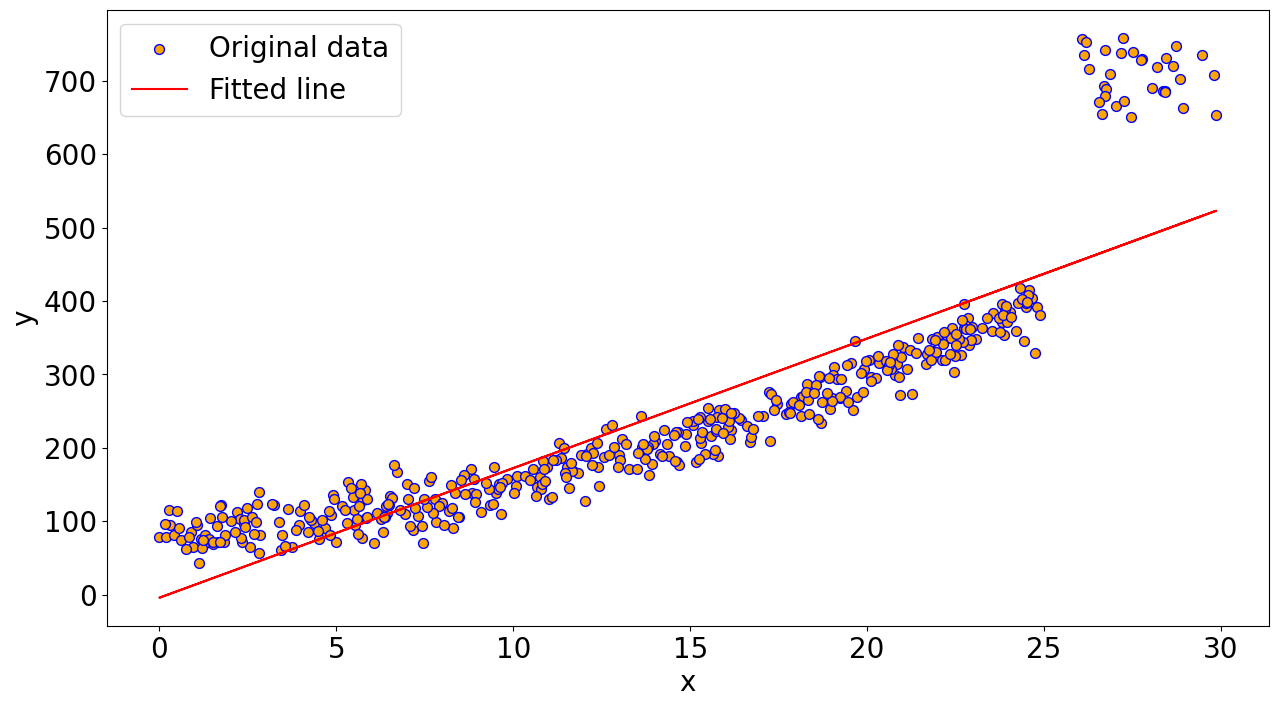

In [15]:
import torch
import numpy as np
import matplotlib.pyplot as plt


# Convert scaled data to PyTorch tensors
X = torch.tensor(X_train, dtype=torch.float32)
Y = torch.tensor(y_train, dtype=torch.float32)

# Initialize parameters (weights)
w_1 = torch.randn(1, requires_grad=True, dtype=torch.float32)  # Weight for X
w_0 = torch.randn(1, requires_grad=True, dtype=torch.float32)  # Bias term

# Lists to store w_1, w_0 values over epochs
w_1_vals = []
w_0_vals = []

# Define the Linear Regression model manually
def model(X):
    return w_1 * X + w_0

# Loss function: Mean Squared Error
def mse_loss_with_l1(Y_pred, Y_true, w_1, w_0, l1_lambda):
    # Mean Squared Error
    mse = torch.mean((Y_pred - Y_true)**2)
    # L1 Regularization term
    l1_penalty = l1_lambda * (torch.abs(w_1) + torch.abs(w_0))
    # Total loss
    return mse + l1_penalty

# Optimizer: Using SGD (Stochastic Gradient Descent)
learning_rate = 0.001  # Adjusted learning rate
epochs = 20000
l1_lambda = 0.1  # Regularization strength (you can tune this)

for epoch in range(epochs):
    # Forward pass: Compute predicted y
    Y_pred = model(X)
    
    # Compute loss
    loss = mse_loss_with_l1(Y_pred, Y, w_1, w_0, l1_lambda)
    
    # Backward pass: Compute gradients
    loss.backward()
    
    # Update parameters manually
    with torch.no_grad():
        w_1 -= learning_rate * w_1.grad
        w_0 -= learning_rate * w_0.grad
        
        # Zero the gradients after updating
        w_1.grad.zero_()
        w_0.grad.zero_()
        
    # Store the values of w_1 and w_0 at each epoch
    w_1_vals.append(w_1.item())
    w_0_vals.append(w_0.item())
    
    # Print the loss every 10 epochs
    if (epoch+1) % 1000 == 0:
        print(f'Epoch [{epoch+1}/{epochs}], Loss: {loss.item():.4f}')

# Print the learned parameters
print(f'Learned weight w1: {w_1.item():.4f}')
print(f'Learned weight w0: {w_0.item():.4f}')
# Predict on scaled X
y_pred = model(X).detach().numpy()


# Plot the results
fig, ax = plt.subplots(figsize=(15, 8))
plt.rcParams['font.size'] = 20
plt.scatter(X_train, y_train, label='Original data',  c='orange', edgecolors='blue', s=50)
plt.plot(X_train, y_pred, label='Fitted line', color='red')
plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.show()

In [16]:
# Predictions

# MSE (Mean Squared Error)
MSE = np.mean((y_train - y_pred) ** 2)

print(f'MSE: {MSE}')
# SSE (Sum of Squared Errors)
SSE = np.sum((y_train - y_pred) ** 2)

# SSTO (Total Sum of Squares)
SSTO = np.sum((y_train - np.mean(y_noisy_with_outliers)) ** 2)

# R-squared
R_squared = 1 - (SSE / SSTO)

# Print the R-squared value
print(f'R-squared: {R_squared.item():.4f}')

MSE: 5725.601599885797
R-squared: 0.7761


Essentially, regularization helps when you have high model complexity relative to data and overfitting is occuring. In the latter situation above, regularization doesn't help when we are fitting only a linear model with polynomial degree of freedom 1 and their is outlier contamination.

# 5. Where does Regularization Help In Case of Linear Model $W_0 + W_1 X$

The case where multicollinearity and high variance, where the model overfits due to correlated features can be mitigated by regularization.

Creating dataset with 30 features and only 100 samples
Features are highly correlated - this causes overfitting.

Training samples: 67
Testing samples: 33
Number of features: 30
Ratio features/samples: 0.45 (should not be too high for ordinary least square regression.)

WITHOUT REGULARIZATION
Training MSE: 1.04
Testing MSE:  8.09
Overfitting gap: 7.04
Max coefficient magnitude: 3.71
Coefficient std dev: 1.32 (high = unstable!)

WITH REGULARIZATION (alpha=10)
Training MSE: 2.50
Testing MSE:  5.99
Overfitting gap: 3.48
Max coefficient magnitude: 1.23
Coefficient std dev: 0.44 (lower = more stable.)

RESULTS SUMMARY
Test MSE Improvement: 26.0%
Ridge achieves 26.0% lower test error.
Ridge prevents overfitting by shrinking extreme coefficients caused by multicollinearity and high dimensionality.



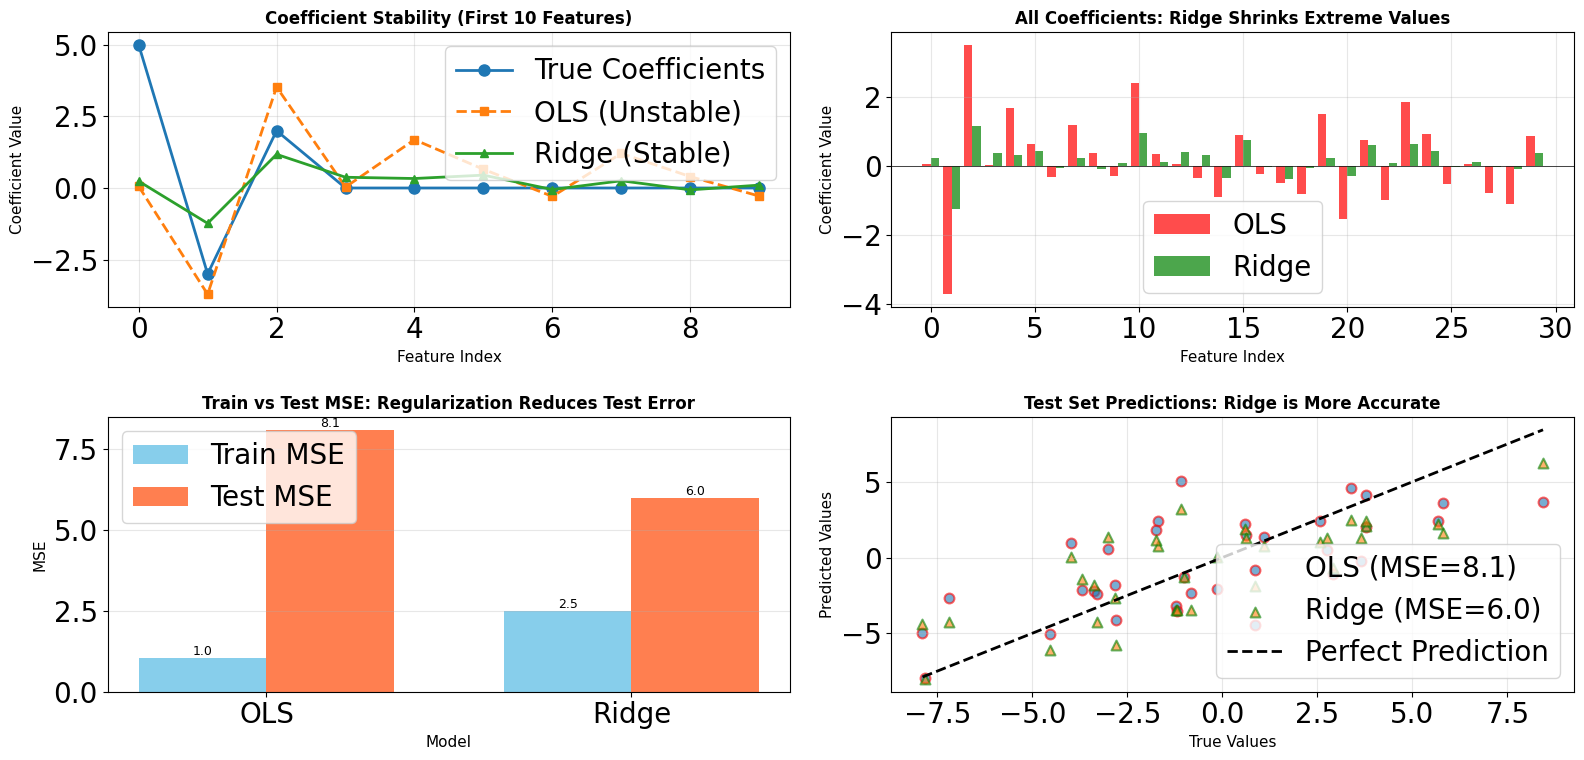

In [24]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.model_selection import train_test_split
import sklearn.metrics as sm

# Set seed for reproducibility
np.random.seed(42)

# Create a HIGH-DIMENSIONAL problem with SMALL dataset
# This is where regularization shines!
n_samples = 100      # Small number of samples
n_features = 30     # MANY features (more than ideal for this sample size)

# Generate correlated features (multicollinearity)
print(f"Creating dataset with {n_features} features and only {n_samples} samples")
print("Features are highly correlated - this causes overfitting.\n")

X = np.random.randn(n_samples, n_features)

# Make features correlated with each other (creates multicollinearity)
for i in range(1, n_features):
    X[:, i] = 0.7 * X[:, 0] + 0.3 * X[:, i]  # Correlate with first feature

# True relationship: only first 3 features actually matter
true_coefs = np.array([5.0, -3.0, 2.0] + [0.0] * (n_features - 3))
y = X @ true_coefs + np.random.randn(n_samples) * 2  # Add noise

# Split train/test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.33, random_state=0)

print(f"Training samples: {len(X_train)}")
print(f"Testing samples: {len(X_test)}")
print(f"Number of features: {n_features}")
print(f"Ratio features/samples: {n_features/len(X_train):.2f} (should not be too high for ordinary least square regression.)\n")

# ============================================
# WITHOUT REGULARIZATION 
# ============================================
print("="*60)
print("WITHOUT REGULARIZATION")
print("="*60)

ols = LinearRegression()
ols.fit(X_train, y_train)

y_train_pred_ols = ols.predict(X_train)
y_test_pred_ols = ols.predict(X_test)

mse_train_ols = sm.mean_squared_error(y_train, y_train_pred_ols)
mse_test_ols = sm.mean_squared_error(y_test, y_test_pred_ols)

print(f"Training MSE: {mse_train_ols:.2f}")
print(f"Testing MSE:  {mse_test_ols:.2f}")
print(f"Overfitting gap: {mse_test_ols - mse_train_ols:.2f}")
print(f"Max coefficient magnitude: {np.max(np.abs(ols.coef_)):.2f}")
print(f"Coefficient std dev: {np.std(ols.coef_):.2f} (high = unstable!)\n")

# ============================================
# WITH REGULARIZATION (Ridge Regression)
# ============================================
print("="*60)
print("WITH REGULARIZATION (alpha=10)")
print("="*60)

ridge = Ridge(alpha=10.0)
ridge.fit(X_train, y_train)

y_train_pred_ridge = ridge.predict(X_train)
y_test_pred_ridge = ridge.predict(X_test)

mse_train_ridge = sm.mean_squared_error(y_train, y_train_pred_ridge)
mse_test_ridge = sm.mean_squared_error(y_test, y_test_pred_ridge)

print(f"Training MSE: {mse_train_ridge:.2f}")
print(f"Testing MSE:  {mse_test_ridge:.2f}")
print(f"Overfitting gap: {mse_test_ridge - mse_train_ridge:.2f}")
print(f"Max coefficient magnitude: {np.max(np.abs(ridge.coef_)):.2f}")
print(f"Coefficient std dev: {np.std(ridge.coef_):.2f} (lower = more stable.)\n")

# ============================================
# RESULTS SUMMARY
# ============================================
print("="*60)
print("RESULTS SUMMARY")
print("="*60)
improvement = (mse_test_ols - mse_test_ridge) / mse_test_ols * 100
print(f"Test MSE Improvement: {improvement:.1f}%")
print(f"Ridge achieves {improvement:.1f}% lower test error.")
print(f"Ridge prevents overfitting by shrinking extreme coefficients caused by multicollinearity and high dimensionality.\n")

# ============================================
# VISUALIZATION
# ============================================
fig, axes = plt.subplots(2, 2, figsize=(16, 8))

# Plot 1: Coefficient comparison (first 10 features)
ax1 = axes[0, 0]
feature_idx = np.arange(10)
ax1.plot(feature_idx, true_coefs[:10], 'o-', label='True Coefficients', linewidth=2, markersize=8)
ax1.plot(feature_idx, ols.coef_[:10], 's--', label='OLS (Unstable)', linewidth=2, markersize=6)
ax1.plot(feature_idx, ridge.coef_[:10], '^-', label='Ridge (Stable)', linewidth=2, markersize=6)
ax1.set_xlabel('Feature Index', fontsize=11)
ax1.set_ylabel('Coefficient Value', fontsize=11)
ax1.set_title('Coefficient Stability (First 10 Features)', fontsize=12, fontweight='bold')
ax1.legend()
ax1.grid(alpha=0.3)

# Plot 2: All coefficients distribution
ax2 = axes[0, 1]
ax2.bar(np.arange(n_features) - 0.2, ols.coef_, 0.4, label='OLS', alpha=0.7, color='red')
ax2.bar(np.arange(n_features) + 0.2, ridge.coef_, 0.4, label='Ridge', alpha=0.7, color='green')
ax2.axhline(y=0, color='black', linestyle='-', linewidth=0.5)
ax2.set_xlabel('Feature Index', fontsize=11)
ax2.set_ylabel('Coefficient Value', fontsize=11)
ax2.set_title('All Coefficients: Ridge Shrinks Extreme Values', fontsize=12, fontweight='bold')
ax2.legend()
ax2.grid(alpha=0.3)

# Plot 3: Train vs Test MSE Comparison
ax3 = axes[1, 0]
models = ['OLS', 'Ridge']
train_mse = [mse_train_ols, mse_train_ridge]
test_mse = [mse_test_ols, mse_test_ridge]

x_pos = np.arange(len(models))
width = 0.35

bars1 = ax3.bar(x_pos - width/2, train_mse, width, label='Train MSE', color='skyblue')
bars2 = ax3.bar(x_pos + width/2, test_mse, width, label='Test MSE', color='coral')

ax3.set_xlabel('Model', fontsize=11)
ax3.set_ylabel('MSE', fontsize=11)
ax3.set_title('Train vs Test MSE: Regularization Reduces Test Error', fontsize=12, fontweight='bold')
ax3.set_xticks(x_pos)
ax3.set_xticklabels(models)
ax3.legend()
ax3.grid(alpha=0.3, axis='y')

# Add value labels on bars
for bars in [bars1, bars2]:
    for bar in bars:
        height = bar.get_height()
        ax3.text(bar.get_x() + bar.get_width()/2., height,
                f'{height:.1f}', ha='center', va='bottom', fontsize=9)

# Plot 4: Predictions comparison
ax4 = axes[1, 1]
ax4.scatter(y_test, y_test_pred_ols, alpha=0.6, label=f'OLS (MSE={mse_test_ols:.1f})', s=50, edgecolors='red', linewidth=1.5)
ax4.scatter(y_test, y_test_pred_ridge, alpha=0.6, label=f'Ridge (MSE={mse_test_ridge:.1f})', s=50, edgecolors='green', linewidth=1.5, marker='^')
ax4.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'k--', lw=2, label='Perfect Prediction')
ax4.set_xlabel('True Values', fontsize=11)
ax4.set_ylabel('Predicted Values', fontsize=11)
ax4.set_title('Test Set Predictions: Ridge is More Accurate', fontsize=12, fontweight='bold')
ax4.legend()
ax4.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('regularization_helps_demo.png', dpi=150, bbox_inches='tight')
plt.show()


In this case, Ridge regression achieves LOWER test MSE by preventing the model from learning noise in the training data.

When you have many features relative to samples, ordinary least square without regularization tries to fit noise.  Correlated features make coefficients unstable and extreme.  Correlated features make coefficients unstable and extreme. However, with ridge regression, the training prevents extreme weights, improving generalization.

## PyTorch Implementation

Epoch [500/5000], Train Loss: 5.5498, Test Loss: 9.4040
Epoch [1000/5000], Train Loss: 4.4376, Test Loss: 8.8492
Epoch [1500/5000], Train Loss: 3.7544, Test Loss: 8.5200
Epoch [2000/5000], Train Loss: 3.2483, Test Loss: 8.2648
Epoch [2500/5000], Train Loss: 2.8572, Test Loss: 8.0639
Epoch [3000/5000], Train Loss: 2.5509, Test Loss: 7.9080
Epoch [3500/5000], Train Loss: 2.3087, Test Loss: 7.7884
Epoch [4000/5000], Train Loss: 2.1156, Test Loss: 7.6975
Epoch [4500/5000], Train Loss: 1.9604, Test Loss: 7.6294
Epoch [5000/5000], Train Loss: 1.8345, Test Loss: 7.5790

Final Training MSE: 1.8343
Final Testing MSE: 7.5790
Overfitting gap: 5.7447
Max weight magnitude: 2.1739

TRAINING WITH L2 REGULARIZATION (Ridge)
Epoch [500/5000], Train Loss: 5.8474, Test Loss: 7.0009
Epoch [1000/5000], Train Loss: 4.6086, Test Loss: 6.2605
Epoch [1500/5000], Train Loss: 4.1240, Test Loss: 6.0669
Epoch [2000/5000], Train Loss: 3.9145, Test Loss: 6.0250
Epoch [2500/5000], Train Loss: 3.8165, Test Loss: 6.0219

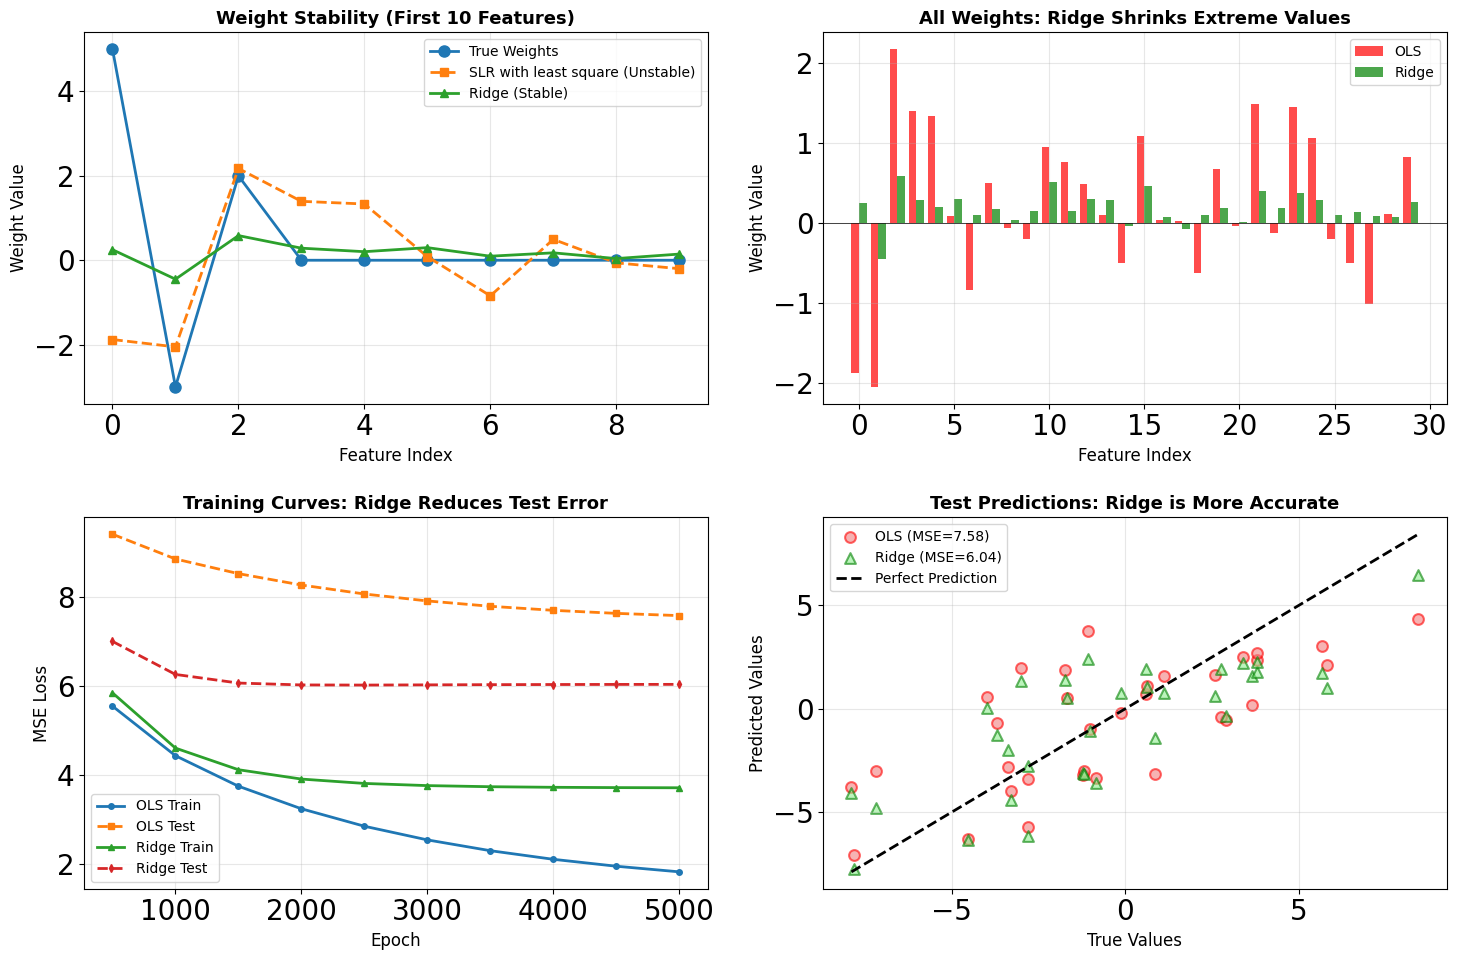

In [26]:
# Convert to PyTorch tensors
X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train, dtype=torch.float32).reshape(-1, 1)
X_test_tensor = torch.tensor(X_test, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test, dtype=torch.float32).reshape(-1, 1)

# Initialize parameters (weights) for all features
w_ols = torch.randn(n_features, 1, requires_grad=True, dtype=torch.float32)
b_ols = torch.randn(1, requires_grad=True, dtype=torch.float32)

# Define the model
def model(X, w, b):
    return X @ w + b

# Loss function: Mean Squared Error (no regularization)
def mse_loss(Y_pred, Y_true):
    return torch.mean((Y_pred - Y_true)**2)

# Training parameters
learning_rate = 0.001
epochs = 5000

train_losses_ols = []
test_losses_ols = []

for epoch in range(epochs):
    # Forward pass
    Y_pred_train = model(X_train_tensor, w_ols, b_ols)
    
    # Compute loss
    loss = mse_loss(Y_pred_train, y_train_tensor)
    
    # Backward pass
    loss.backward()
    
    # Update parameters
    with torch.no_grad():
        w_ols -= learning_rate * w_ols.grad
        b_ols -= learning_rate * b_ols.grad
        
        w_ols.grad.zero_()
        b_ols.grad.zero_()
    
    # Track losses
    if (epoch+1) % 500 == 0:
        with torch.no_grad():
            Y_pred_test = model(X_test_tensor, w_ols, b_ols)
            test_loss = mse_loss(Y_pred_test, y_test_tensor)
            train_losses_ols.append(loss.item())
            test_losses_ols.append(test_loss.item())
            print(f'Epoch [{epoch+1}/{epochs}], Train Loss: {loss.item():.4f}, Test Loss: {test_loss.item():.4f}')

# Final evaluation
with torch.no_grad():
    Y_pred_train_ols = model(X_train_tensor, w_ols, b_ols)
    Y_pred_test_ols = model(X_test_tensor, w_ols, b_ols)
    
    mse_train_ols = mse_loss(Y_pred_train_ols, y_train_tensor).item()
    mse_test_ols = mse_loss(Y_pred_test_ols, y_test_tensor).item()

print(f'\nFinal Training MSE: {mse_train_ols:.4f}')
print(f'Final Testing MSE: {mse_test_ols:.4f}')
print(f'Overfitting gap: {mse_test_ols - mse_train_ols:.4f}')
print(f'Max weight magnitude: {torch.max(torch.abs(w_ols)).item():.4f}\n')

# ============================================
# PyTorch Implementation WITH Regularization (Ridge)
# ============================================
print("TRAINING WITH L2 REGULARIZATION (Ridge)")

# Initialize new parameters for Ridge
w_ridge = torch.randn(n_features, 1, requires_grad=True, dtype=torch.float32)
b_ridge = torch.randn(1, requires_grad=True, dtype=torch.float32)

# Loss function with L2 regularization
def mse_loss_with_l2(Y_pred, Y_true, w, b, l2_lambda):
    mse = torch.mean((Y_pred - Y_true)**2)
    # L2 penalty on weights (typically don't regularize bias)
    l2_penalty = l2_lambda * torch.sum(w**2)
    return mse + l2_penalty

# Training parameters
l2_lambda = 0.5  # Regularization strength
train_losses_ridge = []
test_losses_ridge = []

for epoch in range(epochs):
    # Forward pass
    Y_pred_train = model(X_train_tensor, w_ridge, b_ridge)
    
    # Compute loss with regularization
    loss = mse_loss_with_l2(Y_pred_train, y_train_tensor, w_ridge, b_ridge, l2_lambda)
    
    # Backward pass
    loss.backward()
    
    # Update parameters
    with torch.no_grad():
        w_ridge -= learning_rate * w_ridge.grad
        b_ridge -= learning_rate * b_ridge.grad
        
        w_ridge.grad.zero_()
        b_ridge.grad.zero_()
    
    # Track losses
    if (epoch+1) % 500 == 0:
        with torch.no_grad():
            Y_pred_test = model(X_test_tensor, w_ridge, b_ridge)
            test_loss = mse_loss(Y_pred_test, y_test_tensor)  # Pure MSE for comparison
            train_loss_pure = mse_loss(Y_pred_train, y_train_tensor)
            train_losses_ridge.append(train_loss_pure.item())
            test_losses_ridge.append(test_loss.item())
            print(f'Epoch [{epoch+1}/{epochs}], Train Loss: {train_loss_pure.item():.4f}, Test Loss: {test_loss.item():.4f}')

# Final evaluation
with torch.no_grad():
    Y_pred_train_ridge = model(X_train_tensor, w_ridge, b_ridge)
    Y_pred_test_ridge = model(X_test_tensor, w_ridge, b_ridge)
    
    mse_train_ridge = mse_loss(Y_pred_train_ridge, y_train_tensor).item()
    mse_test_ridge = mse_loss(Y_pred_test_ridge, y_test_tensor).item()

print(f'\nFinal Training MSE: {mse_train_ridge:.4f}')
print(f'Final Testing MSE: {mse_test_ridge:.4f}')
print(f'Overfitting gap: {mse_test_ridge - mse_train_ridge:.4f}')
print(f'Max weight magnitude: {torch.max(torch.abs(w_ridge)).item():.4f}\n')


improvement = (mse_test_ols - mse_test_ridge) / mse_test_ols * 100
print(f"Without Regularization - Test MSE: {mse_test_ols:.4f}")
print(f"With Regularization    - Test MSE: {mse_test_ridge:.4f}")
print(f"\nTest MSE Improvement: {improvement:.1f}%")
print(f"Ridge achieves {improvement:.1f}% Lower test error.\n")

# ============================================
# VISUALIZATION
# ============================================
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Plot 1: Weight comparison (first 10 features)
ax1 = axes[0, 0]
w_ols_np = w_ols.detach().numpy().flatten()
w_ridge_np = w_ridge.detach().numpy().flatten()
feature_idx = np.arange(10)

ax1.plot(feature_idx, true_coefs[:10], 'o-', label='True Weights', linewidth=2, markersize=8)
ax1.plot(feature_idx, w_ols_np[:10], 's--', label='SLR with least square (Unstable)', linewidth=2, markersize=6)
ax1.plot(feature_idx, w_ridge_np[:10], '^-', label='Ridge (Stable)', linewidth=2, markersize=6)
ax1.set_xlabel('Feature Index', fontsize=12)
ax1.set_ylabel('Weight Value', fontsize=12)
ax1.set_title('Weight Stability (First 10 Features)', fontsize=13, fontweight='bold')
ax1.legend(fontsize=10)
ax1.grid(alpha=0.3)

# Plot 2: All weights distribution
ax2 = axes[0, 1]
ax2.bar(np.arange(n_features) - 0.2, w_ols_np, 0.4, label='OLS', alpha=0.7, color='red')
ax2.bar(np.arange(n_features) + 0.2, w_ridge_np, 0.4, label='Ridge', alpha=0.7, color='green')
ax2.axhline(y=0, color='black', linestyle='-', linewidth=0.5)
ax2.set_xlabel('Feature Index', fontsize=12)
ax2.set_ylabel('Weight Value', fontsize=12)
ax2.set_title('All Weights: Ridge Shrinks Extreme Values', fontsize=13, fontweight='bold')
ax2.legend(fontsize=10)
ax2.grid(alpha=0.3)

# Plot 3: Training curves
ax3 = axes[1, 0]
epochs_plot = np.arange(500, epochs+1, 500)
ax3.plot(epochs_plot, train_losses_ols, 'o-', label='OLS Train', linewidth=2, markersize=4)
ax3.plot(epochs_plot, test_losses_ols, 's--', label='OLS Test', linewidth=2, markersize=4)
ax3.plot(epochs_plot, train_losses_ridge, '^-', label='Ridge Train', linewidth=2, markersize=4)
ax3.plot(epochs_plot, test_losses_ridge, 'd--', label='Ridge Test', linewidth=2, markersize=4)
ax3.set_xlabel('Epoch', fontsize=12)
ax3.set_ylabel('MSE Loss', fontsize=12)
ax3.set_title('Training Curves: Ridge Reduces Test Error', fontsize=13, fontweight='bold')
ax3.legend(fontsize=10)
ax3.grid(alpha=0.3)

# Plot 4: Test predictions comparison
ax4 = axes[1, 1]
y_test_ols_np = Y_pred_test_ols.detach().numpy().flatten()
y_test_ridge_np = Y_pred_test_ridge.detach().numpy().flatten()
y_test_np = y_test

ax4.scatter(y_test_np, y_test_ols_np, alpha=0.6, label=f'OLS (MSE={mse_test_ols:.2f})', 
            s=60, edgecolors='red', linewidth=1.5, c='lightcoral')
ax4.scatter(y_test_np, y_test_ridge_np, alpha=0.6, label=f'Ridge (MSE={mse_test_ridge:.2f})', 
            s=60, edgecolors='green', linewidth=1.5, marker='^', c='lightgreen')
ax4.plot([y_test_np.min(), y_test_np.max()], [y_test_np.min(), y_test_np.max()], 
         'k--', lw=2, label='Perfect Prediction')
ax4.set_xlabel('True Values', fontsize=12)
ax4.set_ylabel('Predicted Values', fontsize=12)
ax4.set_title('Test Predictions: Ridge is More Accurate', fontsize=13, fontweight='bold')
ax4.legend(fontsize=10)
ax4.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('pytorch_regularization_demo.png', dpi=150, bbox_inches='tight')
plt.show()



# 6. Testing for multicollinearity of the above dataset

Number of feature pairs with |correlation| > 0.7: 435

First 10 highly correlated pairs:
  Feature 0 & Feature 1: correlation = 0.8896
  Feature 0 & Feature 2: correlation = 0.9346
  Feature 0 & Feature 3: correlation = 0.9209
  Feature 0 & Feature 4: correlation = 0.9123
  Feature 0 & Feature 5: correlation = 0.8894
  Feature 0 & Feature 6: correlation = 0.9145
  Feature 0 & Feature 7: correlation = 0.8908
  Feature 0 & Feature 8: correlation = 0.9282
  Feature 0 & Feature 9: correlation = 0.8873
  Feature 0 & Feature 10: correlation = 0.9109


Text(56.722222222222214, 0.5, 'Feature Index')

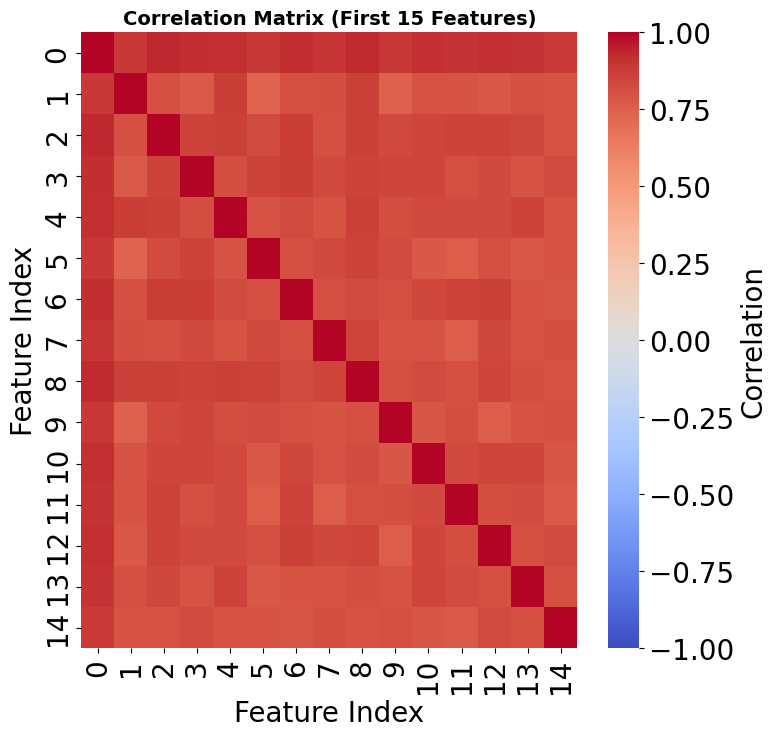

In [30]:
# Calculate correlation matrix
import seaborn as sns
corr_matrix = np.corrcoef(X_train.T)

# Find high correlations (excluding diagonal)
high_corr_pairs = []
for i in range(n_features):
    for j in range(i+1, n_features):
        if abs(corr_matrix[i, j]) > 0.7:
            high_corr_pairs.append((i, j, corr_matrix[i, j]))

print(f"Number of feature pairs with |correlation| > 0.7: {len(high_corr_pairs)}")
print("\nFirst 10 highly correlated pairs:")
for i, j, corr in high_corr_pairs[:10]:
    print(f"  Feature {i} & Feature {j}: correlation = {corr:.4f}")

# Visualize correlation matrix (first 15 features for clarity)
fig, ax1 = plt.subplots(1, 1, figsize=(8, 8))


sns.heatmap(corr_matrix[:15, :15], annot=False, cmap='coolwarm', center=0, 
            vmin=-1, vmax=1, ax=ax1, cbar_kws={'label': 'Correlation'})
ax1.set_title('Correlation Matrix (First 15 Features)', fontsize=14, fontweight='bold')
ax1.set_xlabel('Feature Index')
ax1.set_ylabel('Feature Index')

METHOD 1: CORRELATION MATRIX
High correlations (>0.7 or <-0.7) indicate multicollinearity

Number of feature pairs with |correlation| > 0.7: 435

First 10 highly correlated pairs:
  Feature 0 & Feature 1: correlation = 0.8896
  Feature 0 & Feature 2: correlation = 0.9346
  Feature 0 & Feature 3: correlation = 0.9209
  Feature 0 & Feature 4: correlation = 0.9123
  Feature 0 & Feature 5: correlation = 0.8894
  Feature 0 & Feature 6: correlation = 0.9145
  Feature 0 & Feature 7: correlation = 0.8908
  Feature 0 & Feature 8: correlation = 0.9282
  Feature 0 & Feature 9: correlation = 0.8873
  Feature 0 & Feature 10: correlation = 0.9109

METHOD 2: VARIANCE INFLATION FACTOR (VIF)
VIF > 10: High multicollinearity
VIF > 5: Moderate multicollinearity
VIF < 5: Low multicollinearity

Mean VIF: 14.94
Max VIF: 190.89
Features with VIF > 10: 5
Features with VIF > 5: 30

VIF for first 10 features:
  Feature 0: VIF = 190.89 [HIGH]
  Feature 1: VIF = 9.69 [MODERATE]
  Feature 2: VIF = 12.64 [HIGH]
  F

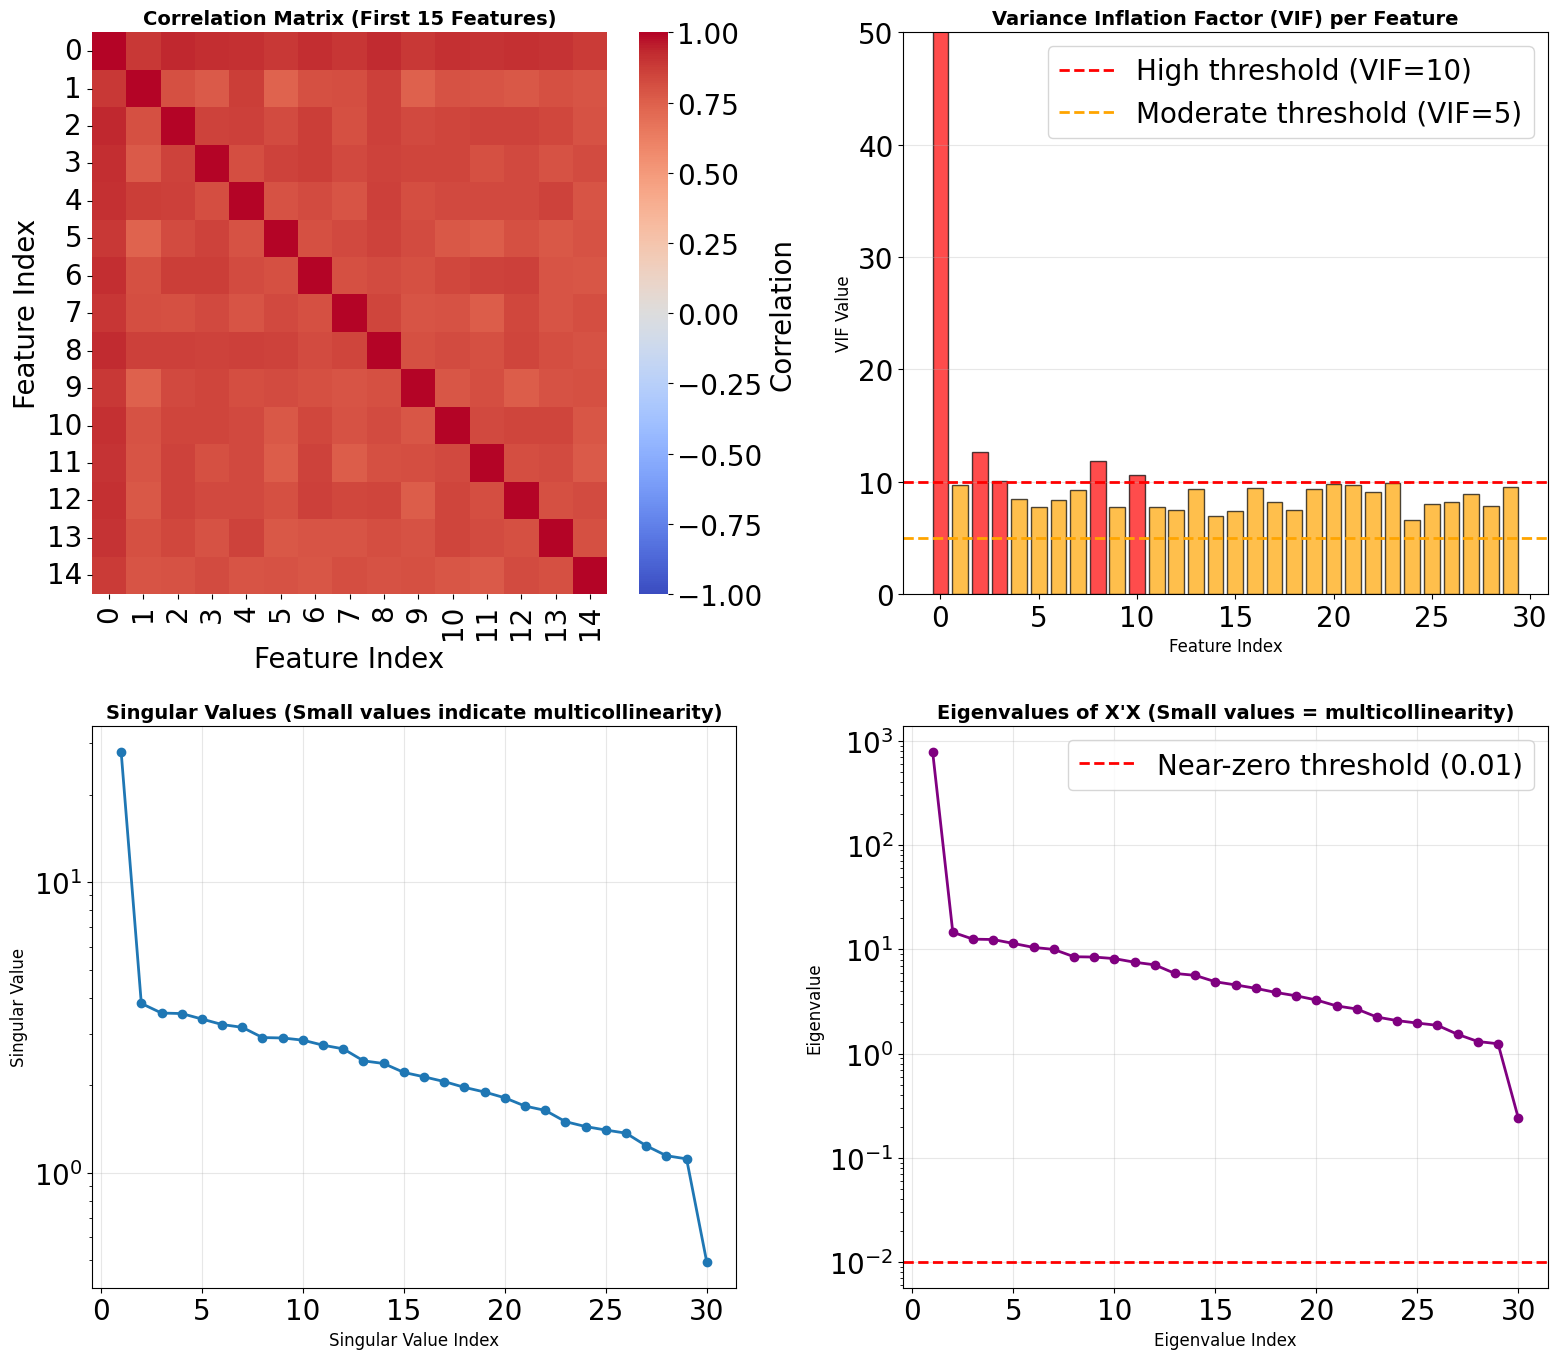

In [33]:
# ============================================
# METHOD 1: CORRELATION MATRIX
# ============================================
print("="*70)
print("METHOD 1: CORRELATION MATRIX")
print("="*70)
print("High correlations (>0.7 or <-0.7) indicate multicollinearity\n")

# Calculate correlation matrix
corr_matrix = np.corrcoef(X_train.T)

# Find high correlations (excluding diagonal)
high_corr_pairs = []
for i in range(n_features):
    for j in range(i+1, n_features):
        if abs(corr_matrix[i, j]) > 0.7:
            high_corr_pairs.append((i, j, corr_matrix[i, j]))

print(f"Number of feature pairs with |correlation| > 0.7: {len(high_corr_pairs)}")
print("\nFirst 10 highly correlated pairs:")
for i, j, corr in high_corr_pairs[:10]:
    print(f"  Feature {i} & Feature {j}: correlation = {corr:.4f}")

# Visualize correlation matrix (first 15 features for clarity)
fig, axes = plt.subplots(2, 2, figsize=(16, 14))

ax1 = axes[0, 0]
sns.heatmap(corr_matrix[:15, :15], annot=False, cmap='coolwarm', center=0, 
            vmin=-1, vmax=1, ax=ax1, cbar_kws={'label': 'Correlation'})
ax1.set_title('Correlation Matrix (First 15 Features)', fontsize=14, fontweight='bold')
ax1.set_xlabel('Feature Index')
ax1.set_ylabel('Feature Index')

# ============================================
# METHOD 2: VARIANCE INFLATION FACTOR (VIF)
# ============================================
print("\n" + "="*70)
print("METHOD 2: VARIANCE INFLATION FACTOR (VIF)")
print("="*70)
print("VIF > 10: High multicollinearity")
print("VIF > 5: Moderate multicollinearity")
print("VIF < 5: Low multicollinearity\n")

def calculate_vif(X):
    """
    Calculate VIF for each feature
    VIF_j = 1 / (1 - R²_j)
    where R²_j is the R² when regressing feature j on all other features
    """
    vif_values = []
    n_features = X.shape[1]
    
    for i in range(n_features):
        # Get all features except i
        X_without_i = np.delete(X, i, axis=1)
        y_i = X[:, i]
        
        # Fit linear regression: predict feature i using all other features
        try:
            # Using normal equation: w = (X'X)^-1 X'y
            XtX = X_without_i.T @ X_without_i
            Xty = X_without_i.T @ y_i
            w = np.linalg.solve(XtX, Xty)
            
            # Calculate R²
            y_pred = X_without_i @ w
            ss_res = np.sum((y_i - y_pred)**2)
            ss_tot = np.sum((y_i - np.mean(y_i))**2)
            r_squared = 1 - (ss_res / ss_tot)
            
            # Calculate VIF
            if r_squared < 0.9999:  # Avoid division by very small number
                vif = 1 / (1 - r_squared)
            else:
                vif = np.inf
            
            vif_values.append(vif)
        except:
            vif_values.append(np.inf)
    
    return np.array(vif_values)

vif_values = calculate_vif(X_train)

print(f"Mean VIF: {np.mean(vif_values[vif_values < np.inf]):.2f}")
print(f"Max VIF: {np.max(vif_values[vif_values < np.inf]):.2f}")
print(f"Features with VIF > 10: {np.sum(vif_values > 10)}")
print(f"Features with VIF > 5: {np.sum(vif_values > 5)}")

print("\nVIF for first 10 features:")
for i in range(min(10, len(vif_values))):
    status = "HIGH" if vif_values[i] > 10 else ("MODERATE" if vif_values[i] > 5 else "LOW")
    print(f"  Feature {i}: VIF = {vif_values[i]:.2f} [{status}]")

# Plot VIF values
ax2 = axes[0, 1]
colors = ['red' if v > 10 else ('orange' if v > 5 else 'green') for v in vif_values]
bars = ax2.bar(range(len(vif_values)), vif_values, color=colors, alpha=0.7, edgecolor='black')
ax2.axhline(y=10, color='red', linestyle='--', linewidth=2, label='High threshold (VIF=10)')
ax2.axhline(y=5, color='orange', linestyle='--', linewidth=2, label='Moderate threshold (VIF=5)')
ax2.set_xlabel('Feature Index', fontsize=12)
ax2.set_ylabel('VIF Value', fontsize=12)
ax2.set_title('Variance Inflation Factor (VIF) per Feature', fontsize=14, fontweight='bold')
ax2.legend()
ax2.grid(alpha=0.3, axis='y')
ax2.set_ylim([0, min(50, np.max(vif_values[vif_values < np.inf]) + 5)])

# ============================================
# METHOD 3: CONDITION NUMBER
# ============================================
print("\n" + "="*70)
print("METHOD 3: CONDITION NUMBER")
print("="*70)
print("Condition Number < 30: Low multicollinearity")
print("Condition Number 30-100: Moderate multicollinearity")
print("Condition Number > 100: High multicollinearity\n")

# Calculate condition number using SVD
U, s, Vt = np.linalg.svd(X_train, full_matrices=False)
condition_number = s[0] / s[-1]

print(f"Condition Number: {condition_number:.2f}")
if condition_number > 100:
    print("HIGH multicollinearity detected!")
elif condition_number > 30:
    print("MODERATE multicollinearity detected!")
else:
    print("✓ LOW multicollinearity")

# Plot singular values
ax3 = axes[1, 0]
ax3.plot(range(1, len(s)+1), s, 'o-', linewidth=2, markersize=6)
ax3.set_xlabel('Singular Value Index', fontsize=12)
ax3.set_ylabel('Singular Value', fontsize=12)
ax3.set_title('Singular Values (Small values indicate multicollinearity)', fontsize=14, fontweight='bold')
ax3.grid(alpha=0.3)
ax3.set_yscale('log')

# ============================================
# METHOD 4: EIGENVALUES OF X'X
# ============================================
print("\n" + "="*70)
print("METHOD 4: EIGENVALUES OF X'X")
print("="*70)
print("Small eigenvalues (close to 0) indicate multicollinearity\n")

# Calculate eigenvalues
XtX = X_train.T @ X_train
eigenvalues = np.linalg.eigvalsh(XtX)
eigenvalues = np.sort(eigenvalues)[::-1]  # Sort in descending order

print(f"Largest eigenvalue: {eigenvalues[0]:.2f}")
print(f"Smallest eigenvalue: {eigenvalues[-1]:.6f}")
print(f"Ratio (largest/smallest): {eigenvalues[0]/eigenvalues[-1]:.2f}")
print(f"Number of near-zero eigenvalues (<0.01): {np.sum(eigenvalues < 0.01)}")

# Plot eigenvalues
ax4 = axes[1, 1]
ax4.plot(range(1, len(eigenvalues)+1), eigenvalues, 'o-', linewidth=2, markersize=6, color='purple')
ax4.axhline(y=0.01, color='red', linestyle='--', linewidth=2, label='Near-zero threshold (0.01)')
ax4.set_xlabel('Eigenvalue Index', fontsize=12)
ax4.set_ylabel('Eigenvalue', fontsize=12)
ax4.set_title('Eigenvalues of X\'X (Small values = multicollinearity)', fontsize=14, fontweight='bold')
ax4.set_yscale('log')
ax4.legend()
ax4.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('multicollinearity_tests.png', dpi=150, bbox_inches='tight')
plt.show()


$$
\text{VIF}_j = \frac{1}{1 - R_j^2}
$$

$$

R_j^2 = 1 - \frac{\text{SS}_{\text{res}}}{\text{SS}_{\text{tot}}}
$$

$$
\text{SS}_{\text{res}} = \sum_{i=1}^{n} (x_{ij} - \hat{x}_{ij})^2
$$

$$
\text{SS}_{\text{tot}} = \sum_{i=1}^{n} (x_{ij} - \bar{x}_j)^2
$$

The Variance Inflation Factor (VIF) is a diagnostic tool that measures how much the variance of a regression coefficient is "inflated" due to multicollinearity with other features. The key insight is that when features are correlated with each other, it becomes difficult for the regression algorithm to determine the individual contribution of each feature, leading to unstable and unreliable coefficient estimates. VIF works by treating each feature as a "target" and trying to predict it using all the other features. If a feature can be accurately predicted from the other features, it means that feature is redundant—it doesn't add much new information to the model. For example, if you have features for "height in centimeters," "height in inches," and "height in meters," any one of these can be perfectly predicted from the others because they're just different units of the same measurement. VIF quantifies this redundancy.